In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score)
from sklearn.metrics import (roc_auc_score, roc_curve)
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

In [2]:
df= pd.read_excel("Sports Data.xlsx", sheet_name= "Sports data for DSBA")

In [3]:
df.head()

,Game_number,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,First_selection,Opponent,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,Game_1,Loss,18.0,Day,ODI,3.0,1,3.0,Bowling,Srilanka,...,13.0,3,0.0,2,3.0,6.0,0,54.0,3,1
1,Game_2,Win,24.0,Day,T20,3.0,1,4.0,Batting,Zimbabwe,...,12.0,1,0.0,0,3.0,6.0,0,69.0,2,1
2,Game_3,Loss,24.0,Day and Night,T20,3.0,1,2.0,Bowling,Zimbabwe,...,14.0,4,0.0,0,3.0,6.0,0,69.0,3,1
3,Game_4,Win,24.0,NaN,ODI,2.0,1,2.0,Bowling,Kenya,...,15.0,4,0.0,2,3.0,6.0,0,73.0,3,1
4,Game_5,Loss,24.0,Night,ODI,1.0,1,3.0,Bowling,Srilanka,...,12.0,4,0.0,0,3.0,6.0,0,80.0,3,1


In [4]:
df.tail()

,Game_number,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,First_selection,Opponent,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
2925,Game_2926,Win,30.0,Day,T20,3.0,1,4.0,Batting,South Africa,...,15.0,3,8.0,0,3.0,6.0,3,50.0,3,2
2926,Game_2927,Win,30.0,Day,ODI,4.0,1,3.0,Bowling,Kenya,...,14.0,4,8.0,2,3.0,6.0,2,52.0,2,1
2927,Game_2928,Win,30.0,Day and Night,ODI,4.0,1,3.0,Bowling,Pakistan,...,14.0,4,10.0,2,4.0,10.0,2,80.0,3,2
2928,Game_2929,Win,30.0,Day,ODI,4.0,1,3.0,Batting,Kenya,...,14.0,2,20.0,2,3.0,6.0,3,98.0,3,1
2929,Game_2930,Win,30.0,Day,ODI,4.0,1,3.0,Batting,Kenya,...,12.0,4,4.0,5,3.0,6.0,3,62.0,1,1


In [5]:
df.shape

(2930, 23)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Game_number             2930 non-null   object 
 1   Result                  2930 non-null   object 
 2   Avg_team_Age            2833 non-null   float64
 3   Match_light_type        2878 non-null   object 
 4   Match_format            2860 non-null   object 
 5   Bowlers_in_team         2848 non-null   float64
 6   Wicket_keeper_in_team   2930 non-null   int64  
 7   All_rounder_in_team     2890 non-null   float64
 8   First_selection         2871 non-null   object 
 9   Opponent                2894 non-null   object 
 10  Season                  2868 non-null   object 
 11  Audience_number         2849 non-null   float64
 12  Offshore                2866 non-null   object 
 13  Max_run_scored_1over    2902 non-null   float64
 14  Max_wicket_taken_1over  2930 non-null   

In [7]:
df.isna().sum()

Game_number                0
Result                     0
Avg_team_Age              97
Match_light_type          52
Match_format              70
Bowlers_in_team           82
Wicket_keeper_in_team      0
All_rounder_in_team       40
First_selection           59
Opponent                  36
Season                    62
Audience_number           81
Offshore                  64
Max_run_scored_1over      28
Max_wicket_taken_1over     0
Extra_bowls_bowled        29
Min_run_given_1over        0
Min_run_scored_1over      27
Max_run_given_1over       34
extra_bowls_opponent       0
player_highest_run        28
Players_scored_zero        0
player_highest_wicket      0
dtype: int64

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_team_Age,2833.0,29.242852,2.264230,12.0,30.0,30.0,30.00,70.0
Bowlers_in_team,2848.0,2.913624,1.023907,1.0,2.0,3.0,4.00,5.0
Wicket_keeper_in_team,2930.0,1.000000,0.000000,1.0,1.0,1.0,1.00,1.0
All_rounder_in_team,2890.0,2.722491,1.092699,1.0,2.0,3.0,4.00,4.0
Audience_number,2849.0,46267.960688,48599.581459,7063.0,20363.0,34349.0,57876.00,1399930.0
Max_run_scored_1over,2902.0,15.199862,3.661010,11.0,12.0,14.0,18.00,25.0
Max_wicket_taken_1over,2930.0,2.713993,1.080623,1.0,2.0,3.0,4.00,4.0
Extra_bowls_bowled,2901.0,11.252671,7.780829,0.0,6.0,10.0,15.00,40.0
Min_run_given_1over,2930.0,1.952560,1.678332,0.0,0.0,2.0,3.00,6.0
Min_run_scored_1over,2903.0,2.762659,0.705759,1.0,2.0,3.0,3.00,4.0


In [9]:
df.describe(include='object').T

,count,unique,top,freq
Game_number,2930,2930,Game_1,1
Result,2930,2,Win,2457
Match_light_type,2878,3,Day,2041
Match_format,2860,4,ODI,1865
First_selection,2871,3,Bowling,1722
Opponent,2894,9,South Africa,640
Season,2868,3,Rainy,1309
Offshore,2866,2,No,2057
Players_scored_zero,2930,5,3,1730
player_highest_wicket,2930,6,1,1084


In [10]:
df['Result'].unique()

array(['Loss', 'Win'], dtype=object)

In [11]:
df['Avg_team_Age'].unique()

array([18., 24., nan, 17., 12., 25., 26., 27., 28., 29., 30., 70., 69.,
       50.])

In [12]:
df['Match_light_type'].unique()

array(['Day', 'Day and Night', nan, 'Night'], dtype=object)

In [13]:
df['Match_format'].unique()

array(['ODI', 'T20', 'Test', '20-20', nan], dtype=object)

In [14]:
df['Match_format'].replace('20-20', 'T20', inplace=True)

In [15]:
df['Match_format'].unique()

array(['ODI', 'T20', 'Test', nan], dtype=object)

In [16]:
df['Bowlers_in_team'].unique()

array([ 3.,  2.,  1., nan,  4.,  5.])

In [17]:
df['Wicket_keeper_in_team'].unique()

array([1], dtype=int64)

In [18]:
df['All_rounder_in_team'].unique()

array([ 3.,  4.,  2.,  1., nan])

In [19]:
df['First_selection'].unique()

array(['Bowling', 'Batting', 'Bat', nan], dtype=object)

In [20]:
df['First_selection'].replace('Bat','Batting', inplace=True)

In [21]:
df['First_selection'].unique()

array(['Bowling', 'Batting', nan], dtype=object)

In [22]:
df['Opponent'].unique()

array(['Srilanka', 'Zimbabwe', 'Kenya', 'Australia', 'England',
       'South Africa', 'Pakistan', 'West Indies', 'Bangladesh', nan],
      dtype=object)

In [23]:
df['Season'].unique()

array(['Summer', nan, 'Winter', 'Rainy'], dtype=object)

In [24]:
df['Offshore'].unique()

array(['No', 'Yes', nan], dtype=object)

In [25]:
df['Max_run_scored_1over'].unique()

array([13., 12., 14., 15., 16., 19., 21., 22., 25., 18., 11., 17., 24.,
       20., nan, 23.])

In [26]:
df['Max_wicket_taken_1over'].unique()

array([3, 1, 4, 2], dtype=int64)

In [27]:
df['Extra_bowls_bowled'].unique()

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       17., 31., 13., 26., 24., 22., 19., 23., 14., 15., 29., 28., 21.,
       25., 20., 16., 37., 38., 30., 40., 18., 36., 34., 32., 33., nan,
       35., 27.])

In [28]:
df['Min_run_given_1over'].unique()

array([2, 0, 5, 4, 3, 6, 1], dtype=int64)

In [29]:
df['Min_run_scored_1over'].unique()

array([ 3.,  4.,  1.,  2., nan])

In [30]:
df['Max_run_given_1over'].unique()

array([ 6.,  7.,  8.,  9., 10., 11., 25., 12., 14., 22., 15., 27., 21.,
       17., 13., 37., 16., 20., 40., 24., 33., 19., 36., 18., 29., 31.,
       32., 34., 26., 30., nan, 23.])

In [31]:
df['extra_bowls_opponent'].unique()

array([ 0,  1,  2,  3,  4,  5,  7,  8,  6,  9, 10, 13, 15, 14, 16, 11, 12,
       18, 17], dtype=int64)

In [32]:
df['player_highest_run'].unique()

array([ 54.,  69.,  73.,  80.,  97.,  70.,  33.,  50.,  79., 100.,  47.,
        52.,  37.,  96.,  57.,  66.,  83.,  32.,  49.,  84.,  98.,  87.,
        43.,  31.,  99.,  39.,  90.,  65.,  36.,  45.,  58.,  59.,  60.,
        34.,  94.,  48.,  85.,  75.,  63.,  62.,  93.,  51.,  78.,  61.,
        77.,  38.,  89.,  55.,  46.,  41.,  42.,  91.,  64.,  40.,  67.,
        81.,  68.,  82.,  71.,  88.,  53.,  76.,  95.,  30.,  74.,  56.,
        86.,  44.,  92.,  72.,  35.,  nan])

In [33]:
df['Players_scored_zero'].unique()

array([3, 2, 1, 4, 'Three'], dtype=object)

In [34]:
df['Players_scored_zero'].replace('Three',3, inplace=True)

In [35]:
df['Players_scored_zero'].unique()

array([3, 2, 1, 4], dtype=int64)

In [36]:
df['player_highest_wicket'].unique()

array([1, 2, 3, 4, 'Three', 5], dtype=object)

In [37]:
df['player_highest_wicket'].replace('Three',3, inplace=True)

In [38]:
df['player_highest_wicket'].unique()

array([1, 2, 3, 4, 5], dtype=int64)

### Missing Value Treatment

In [39]:
df.Avg_team_Age.unique()

array([18., 24., nan, 17., 12., 25., 26., 27., 28., 29., 30., 70., 69.,
       50.])

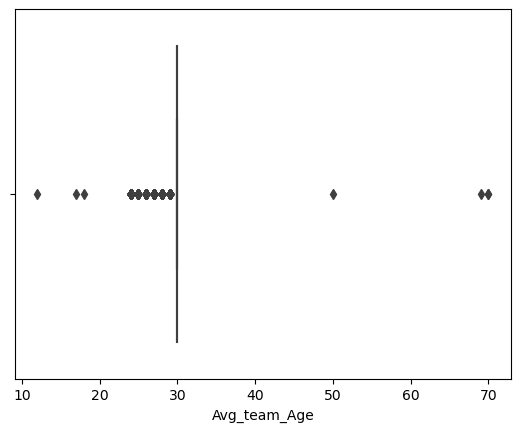

In [40]:
sns.boxplot(x='Avg_team_Age', data=df);

In [41]:
df_num = df.select_dtypes(['float64', 'int64'])
df_cat = df.select_dtypes(['object'])

In [42]:
df_num.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Avg_team_Age            2833 non-null   float64
 1   Bowlers_in_team         2848 non-null   float64
 2   Wicket_keeper_in_team   2930 non-null   int64  
 3   All_rounder_in_team     2890 non-null   float64
 4   Audience_number         2849 non-null   float64
 5   Max_run_scored_1over    2902 non-null   float64
 6   Max_wicket_taken_1over  2930 non-null   int64  
 7   Extra_bowls_bowled      2901 non-null   float64
 8   Min_run_given_1over     2930 non-null   int64  
 9   Min_run_scored_1over    2903 non-null   float64
 10  Max_run_given_1over     2896 non-null   float64
 11  extra_bowls_opponent    2930 non-null   int64  
 12  player_highest_run      2902 non-null   float64
 13  Players_scored_zero     2930 non-null   int64  
 14  player_highest_wicket   2930 non-null   

In [43]:
df_cat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Game_number       2930 non-null   object
 1   Result            2930 non-null   object
 2   Match_light_type  2878 non-null   object
 3   Match_format      2860 non-null   object
 4   First_selection   2871 non-null   object
 5   Opponent          2894 non-null   object
 6   Season            2868 non-null   object
 7   Offshore          2866 non-null   object
dtypes: object(8)
memory usage: 183.3+ KB


In [44]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values= np.nan, strategy= 'median')
imr = SimpleImputer(missing_values= np.nan, strategy= 'most_frequent')

In [45]:
df_num = pd.DataFrame(imputer.fit_transform(df_num), columns = df_num.columns)

In [46]:
df_cat = pd.DataFrame(imr.fit_transform(df_cat), columns = df_cat.columns)

In [47]:
df_num.isnull().sum()

Avg_team_Age              0
Bowlers_in_team           0
Wicket_keeper_in_team     0
All_rounder_in_team       0
Audience_number           0
Max_run_scored_1over      0
Max_wicket_taken_1over    0
Extra_bowls_bowled        0
Min_run_given_1over       0
Min_run_scored_1over      0
Max_run_given_1over       0
extra_bowls_opponent      0
player_highest_run        0
Players_scored_zero       0
player_highest_wicket     0
dtype: int64

In [48]:
df_cat.isnull().sum()

Game_number         0
Result              0
Match_light_type    0
Match_format        0
First_selection     0
Opponent            0
Season              0
Offshore            0
dtype: int64

In [49]:
df_num.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_team_Age,2930.0,29.267918,2.230540,12.0,30.0,30.0,30.00,70.0
Bowlers_in_team,2930.0,2.916041,1.009573,1.0,2.0,3.0,4.00,5.0
Wicket_keeper_in_team,2930.0,1.000000,0.000000,1.0,1.0,1.0,1.00,1.0
All_rounder_in_team,2930.0,2.726280,1.085690,1.0,2.0,3.0,4.00,4.0
Audience_number,2930.0,45938.460410,47962.711339,7063.0,20608.0,34349.0,55931.75,1399930.0
Max_run_scored_1over,2930.0,15.188396,3.645339,11.0,12.0,14.0,18.00,25.0
Max_wicket_taken_1over,2930.0,2.713993,1.080623,1.0,2.0,3.0,4.00,4.0
Extra_bowls_bowled,2930.0,11.240273,7.743208,0.0,6.0,10.0,15.00,40.0
Min_run_given_1over,2930.0,1.952560,1.678332,0.0,0.0,2.0,3.00,6.0
Min_run_scored_1over,2930.0,2.764846,0.702864,1.0,2.0,3.0,3.00,4.0


In [50]:
df_cat.describe().T

,count,unique,top,freq
Game_number,2930,2930,Game_1,1
Result,2930,2,Win,2457
Match_light_type,2930,3,Day,2093
Match_format,2930,3,ODI,1935
First_selection,2930,2,Bowling,1781
Opponent,2930,9,South Africa,676
Season,2930,3,Rainy,1371
Offshore,2930,2,No,2121


In [51]:
df_new = pd.concat([df_num, df_cat], axis=1, join='inner')

In [52]:
df_new.head()

,Avg_team_Age,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,Audience_number,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,...,Players_scored_zero,player_highest_wicket,Game_number,Result,Match_light_type,Match_format,First_selection,Opponent,Season,Offshore
0,18.0,3.0,1.0,3.0,9940.0,13.0,3.0,0.0,2.0,3.0,...,3.0,1.0,Game_1,Loss,Day,ODI,Bowling,Srilanka,Summer,No
1,24.0,3.0,1.0,4.0,8400.0,12.0,1.0,0.0,0.0,3.0,...,2.0,1.0,Game_2,Win,Day,T20,Batting,Zimbabwe,Summer,No
2,24.0,3.0,1.0,2.0,13146.0,14.0,4.0,0.0,0.0,3.0,...,3.0,1.0,Game_3,Loss,Day and Night,T20,Bowling,Zimbabwe,Rainy,Yes
3,24.0,2.0,1.0,2.0,7357.0,15.0,4.0,0.0,2.0,3.0,...,3.0,1.0,Game_4,Win,Day,ODI,Bowling,Kenya,Summer,No
4,24.0,1.0,1.0,3.0,13328.0,12.0,4.0,0.0,0.0,3.0,...,3.0,1.0,Game_5,Loss,Night,ODI,Bowling,Srilanka,Summer,No


In [53]:
df_new.shape

(2930, 23)

In [54]:
df= df_new

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Avg_team_Age            2930 non-null   float64
 1   Bowlers_in_team         2930 non-null   float64
 2   Wicket_keeper_in_team   2930 non-null   float64
 3   All_rounder_in_team     2930 non-null   float64
 4   Audience_number         2930 non-null   float64
 5   Max_run_scored_1over    2930 non-null   float64
 6   Max_wicket_taken_1over  2930 non-null   float64
 7   Extra_bowls_bowled      2930 non-null   float64
 8   Min_run_given_1over     2930 non-null   float64
 9   Min_run_scored_1over    2930 non-null   float64
 10  Max_run_given_1over     2930 non-null   float64
 11  extra_bowls_opponent    2930 non-null   float64
 12  player_highest_run      2930 non-null   float64
 13  Players_scored_zero     2930 non-null   float64
 14  player_highest_wicket   2930 non-null   

In [56]:
int_cols = ['Bowlers_in_team', 'All_rounder_in_team','Min_run_scored_1over','Max_run_scored_1over','Max_run_given_1over', 'Extra_bowls_bowled','Min_run_given_1over','player_highest_run', 'Wicket_keeper_in_team','Max_wicket_taken_1over','extra_bowls_opponent','Players_scored_zero','player_highest_wicket']
df[int_cols] = df[int_cols].astype('Int64')

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Avg_team_Age            2930 non-null   float64
 1   Bowlers_in_team         2930 non-null   Int64  
 2   Wicket_keeper_in_team   2930 non-null   Int64  
 3   All_rounder_in_team     2930 non-null   Int64  
 4   Audience_number         2930 non-null   float64
 5   Max_run_scored_1over    2930 non-null   Int64  
 6   Max_wicket_taken_1over  2930 non-null   Int64  
 7   Extra_bowls_bowled      2930 non-null   Int64  
 8   Min_run_given_1over     2930 non-null   Int64  
 9   Min_run_scored_1over    2930 non-null   Int64  
 10  Max_run_given_1over     2930 non-null   Int64  
 11  extra_bowls_opponent    2930 non-null   Int64  
 12  player_highest_run      2930 non-null   Int64  
 13  Players_scored_zero     2930 non-null   Int64  
 14  player_highest_wicket   2930 non-null   

### Univariate analysis

#### Numerical variable

In [58]:
df[['Avg_team_Age', 'Audience_number', 'Max_run_scored_1over']].describe()

,Avg_team_Age,Audience_number,Max_run_scored_1over
count,2930.000000,2.930000e+03,2930.0
mean,29.267918,4.593846e+04,15.188396
std,2.230540,4.796271e+04,3.645339
min,12.000000,7.063000e+03,11.0
25%,30.000000,2.060800e+04,12.0
50%,30.000000,3.434900e+04,14.0
75%,30.000000,5.593175e+04,18.0
max,70.000000,1.399930e+06,25.0


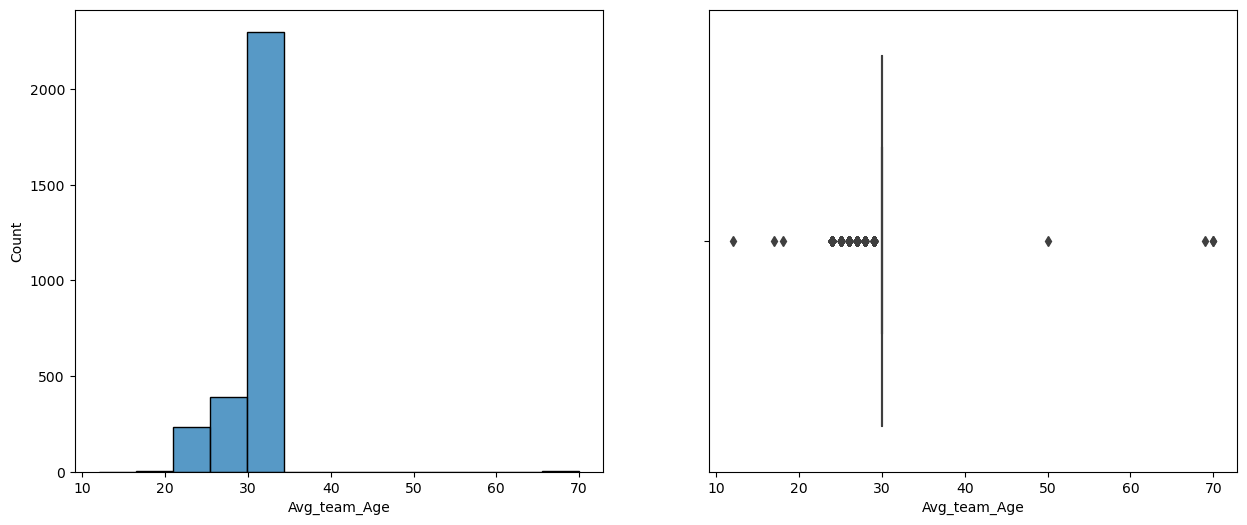

In [59]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['Avg_team_Age'], kde=False, ax=axes[0])
sns.boxplot(x='Avg_team_Age', data=df, ax=axes[1])
plt.show();

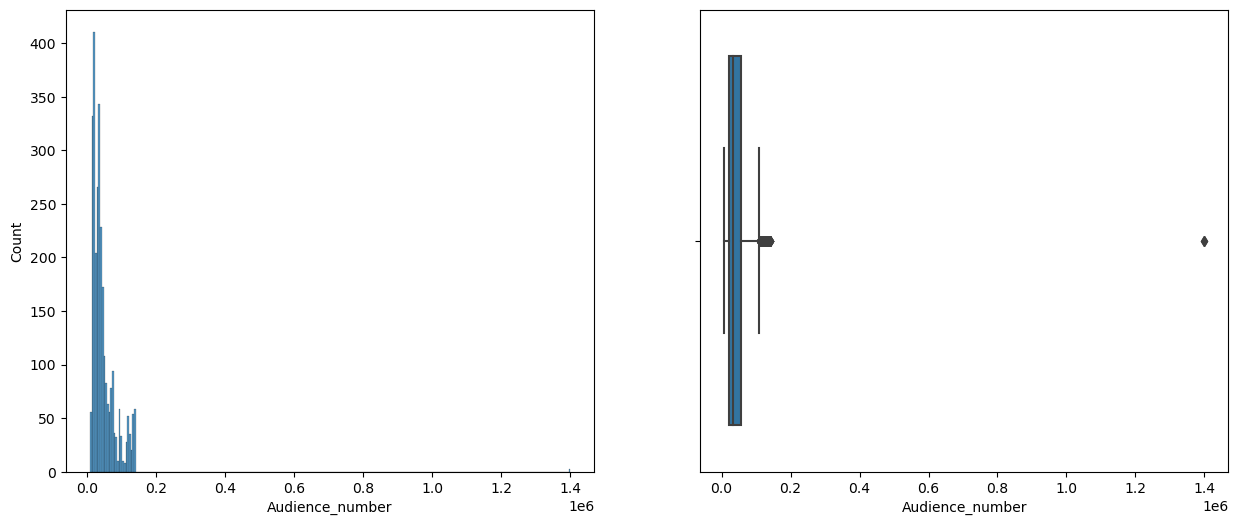

In [60]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['Audience_number'], kde=False, ax=axes[0])
sns.boxplot(x='Audience_number', data=df, ax=axes[1])
plt.show();

D:\Anaconda\Lib\site-packages\seaborn\distributions.py:499: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(edges, name="edges"),
D:\Anaconda\Lib\site-packages\seaborn\distributions.py:500: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(widths, name="widths"),


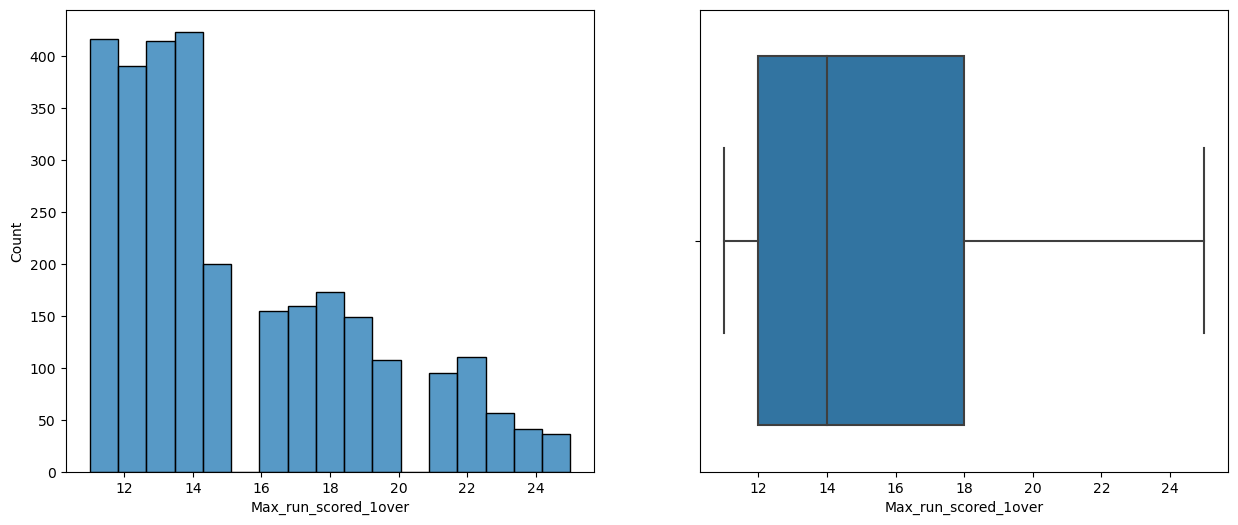

In [61]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['Max_run_scored_1over'], kde=False, ax=axes[0])
sns.boxplot(x='Max_run_scored_1over', data=df, ax=axes[1])
plt.show();

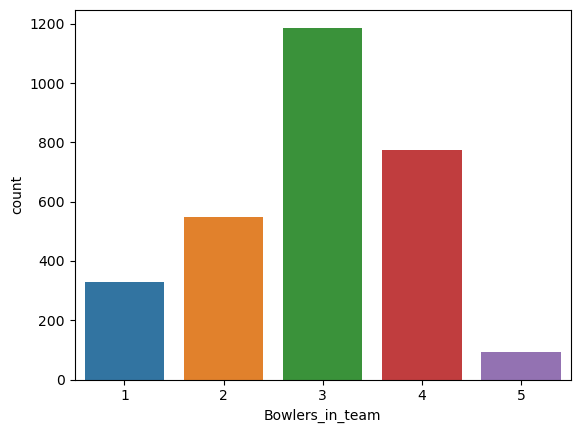

In [62]:
sns.countplot(x='Bowlers_in_team', data=df)
plt.show()

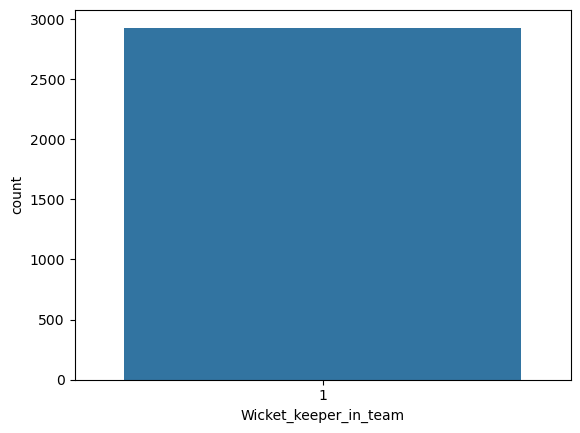

In [63]:
sns.countplot(x='Wicket_keeper_in_team', data=df)
plt.show()

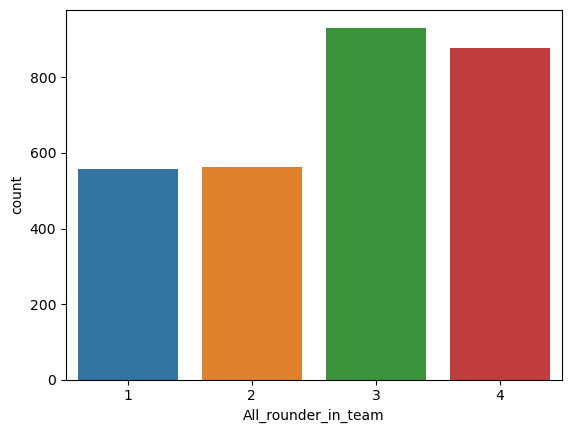

In [64]:
sns.countplot(x='All_rounder_in_team', data=df)
plt.show()

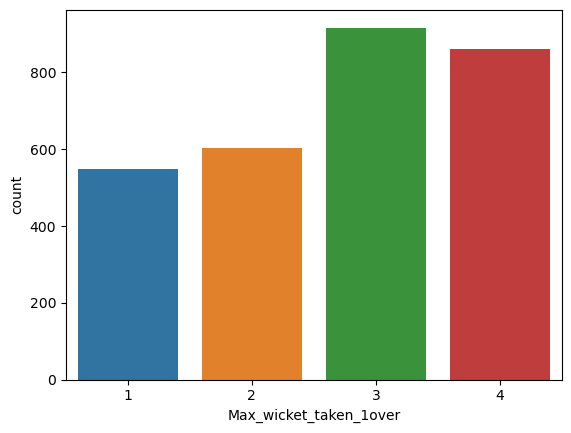

In [65]:
sns.countplot(x='Max_wicket_taken_1over', data=df)
plt.show()

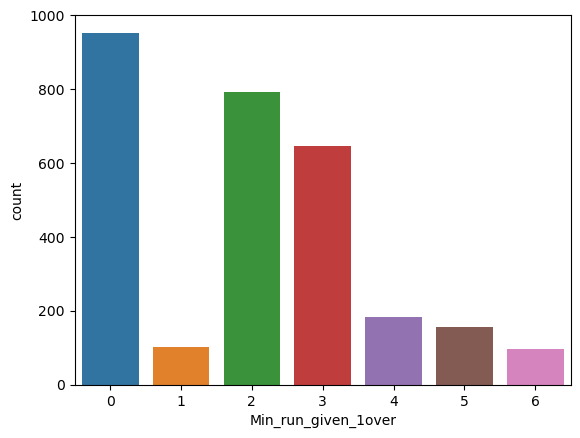

In [66]:
sns.countplot(x='Min_run_given_1over', data=df)
plt.show()

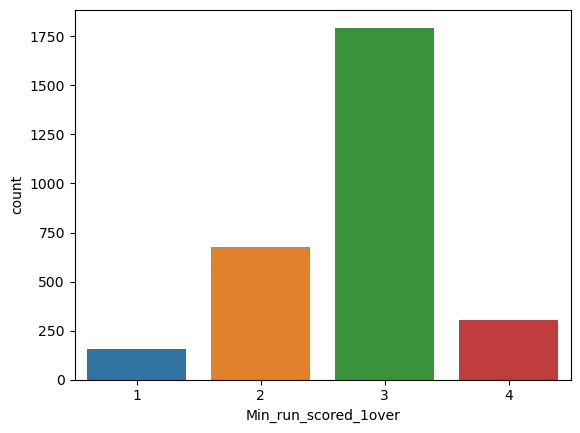

In [67]:
sns.countplot(x='Min_run_scored_1over', data=df)
plt.show()

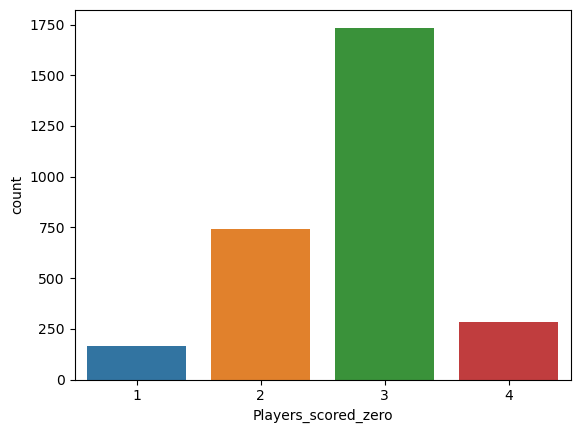

In [68]:
sns.countplot(x='Players_scored_zero', data=df)
plt.show()

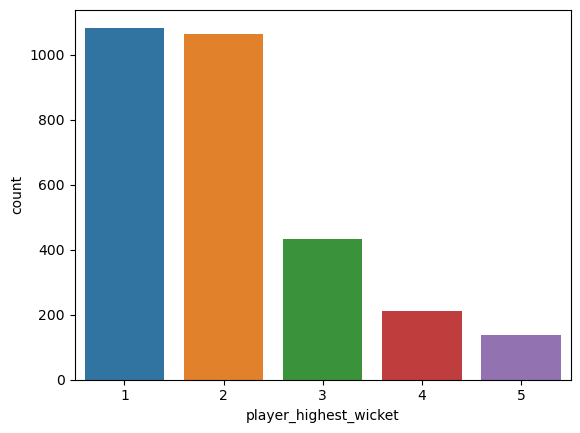

In [69]:
sns.countplot(x='player_highest_wicket', data=df)
plt.show()

D:\Anaconda\Lib\site-packages\seaborn\distributions.py:499: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(edges, name="edges"),
D:\Anaconda\Lib\site-packages\seaborn\distributions.py:500: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(widths, name="widths"),


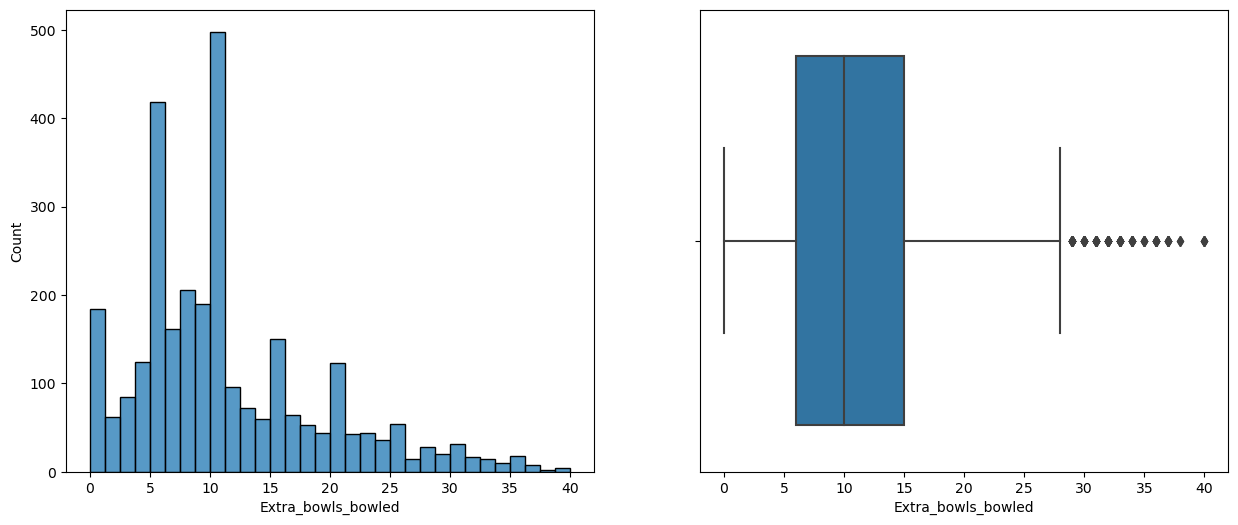

In [70]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['Extra_bowls_bowled'], kde=False, ax=axes[0])
sns.boxplot(x='Extra_bowls_bowled', data=df, ax=axes[1])
plt.show()

D:\Anaconda\Lib\site-packages\seaborn\distributions.py:499: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(edges, name="edges"),
D:\Anaconda\Lib\site-packages\seaborn\distributions.py:500: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(widths, name="widths"),


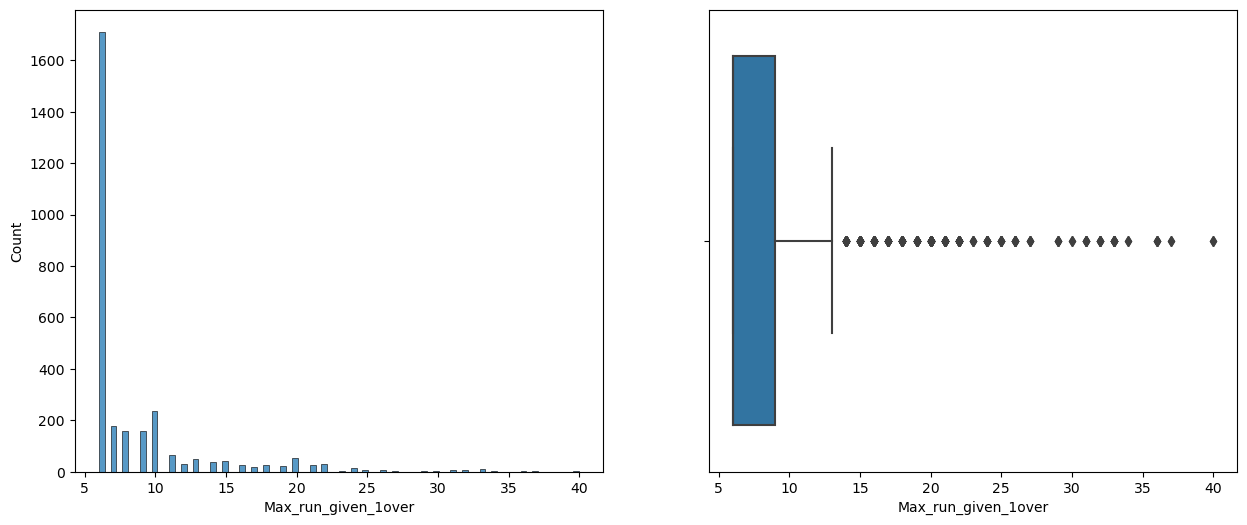

In [71]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['Max_run_given_1over'], kde=False, ax=axes[0])
sns.boxplot(x='Max_run_given_1over', data=df, ax=axes[1])
plt.show()

D:\Anaconda\Lib\site-packages\seaborn\distributions.py:499: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(edges, name="edges"),
D:\Anaconda\Lib\site-packages\seaborn\distributions.py:500: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(widths, name="widths"),


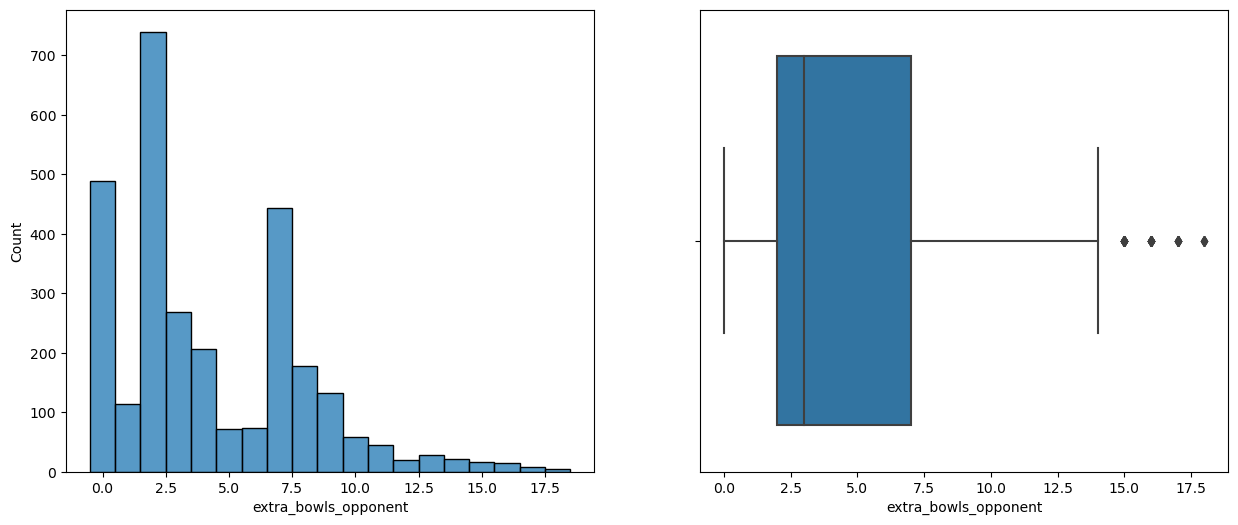

In [72]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['extra_bowls_opponent'], discrete=True, ax=axes[0])
sns.boxplot(x='extra_bowls_opponent', data=df, ax=axes [1])
plt.show()

D:\Anaconda\Lib\site-packages\seaborn\distributions.py:499: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(edges, name="edges"),
D:\Anaconda\Lib\site-packages\seaborn\distributions.py:500: FutureWarning: In a future version, the Index constructor will not infer numeric dtypes when passed object-dtype sequences (matching Series behavior)
  pd.Index(widths, name="widths"),


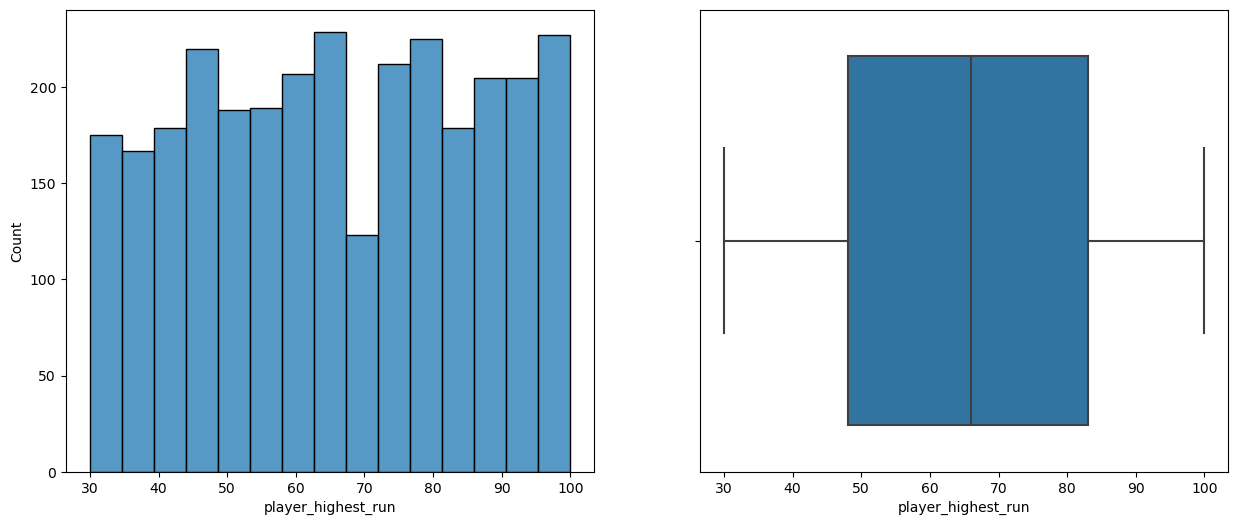

In [73]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,6))
sns.histplot(df['player_highest_run'], ax=axes[0])
sns.boxplot(x='player_highest_run', data=df, ax=axes[1])
plt.show()

#### Target Variable

In [74]:
df['Result'].value_counts()

Win     2457
Loss     473
Name: Result, dtype: int64

In [75]:
df['Result'].value_counts(normalize=True)* 100

Win     83.856655
Loss    16.143345
Name: Result, dtype: float64

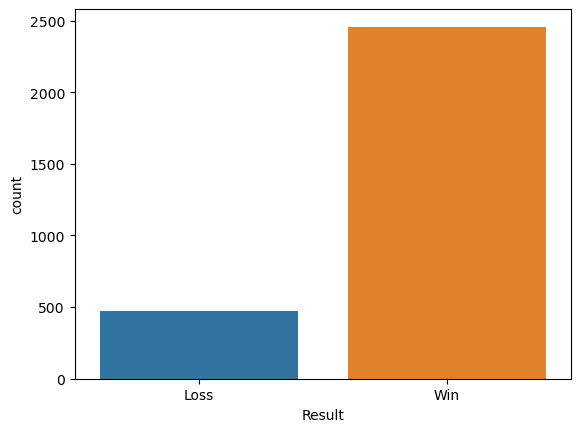

In [76]:
sns.countplot(x='Result', data=df)
plt.show()

#### Categorical Variable

In [77]:
df['Match_light_type'].value_counts()

Day              2093
Day and Night     541
Night             296
Name: Match_light_type, dtype: int64

In [78]:
df['Match_light_type'].value_counts(normalize=True)* 100

Day              71.433447
Day and Night    18.464164
Night            10.102389
Name: Match_light_type, dtype: float64

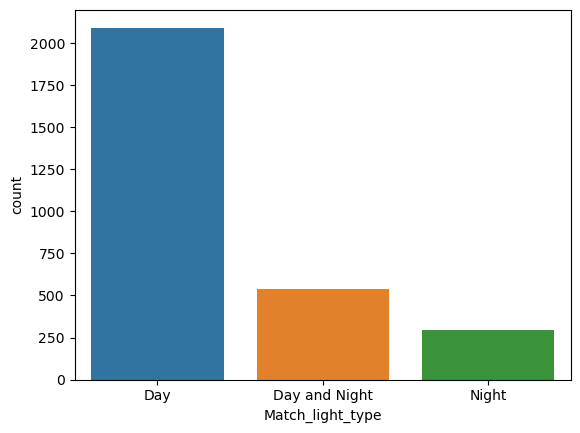

In [79]:
sns.countplot(x='Match_light_type', data=df)
plt.show()

In [80]:
df['Match_format'].value_counts()

ODI     1935
T20      870
Test     125
Name: Match_format, dtype: int64

In [81]:
df['Match_format'].value_counts(normalize=True)* 100

ODI     66.040956
T20     29.692833
Test     4.266212
Name: Match_format, dtype: float64

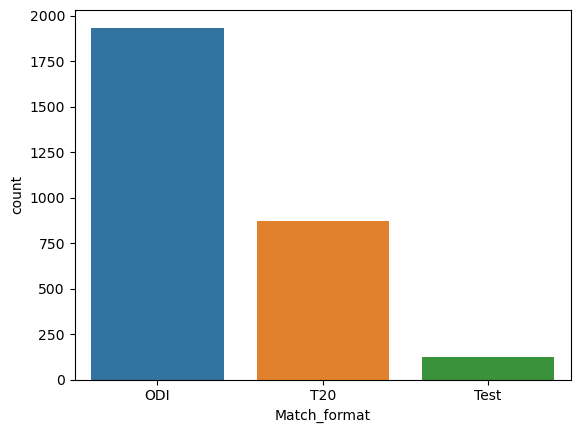

In [82]:
sns.countplot(x='Match_format', data=df)
plt.show()

In [83]:
df['First_selection'].value_counts()

Bowling    1781
Batting    1149
Name: First_selection, dtype: int64

In [84]:
df['First_selection'].value_counts(normalize=True)* 100

Bowling    60.784983
Batting    39.215017
Name: First_selection, dtype: float64

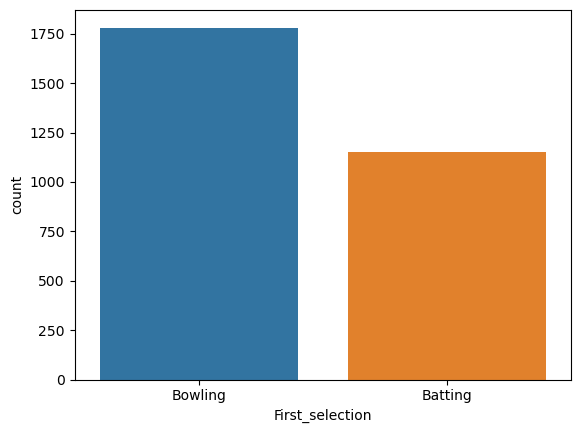

In [85]:
sns.countplot(x='First_selection', data=df)
plt.show()

In [86]:
df['Opponent'].value_counts()

South Africa    676
Kenya           576
Srilanka        513
England         283
Pakistan        253
Bangladesh      204
Zimbabwe        163
West Indies     158
Australia       104
Name: Opponent, dtype: int64

In [87]:
df['Opponent'].value_counts(normalize=True)* 100

South Africa    23.071672
Kenya           19.658703
Srilanka        17.508532
England          9.658703
Pakistan         8.634812
Bangladesh       6.962457
Zimbabwe         5.563140
West Indies      5.392491
Australia        3.549488
Name: Opponent, dtype: float64

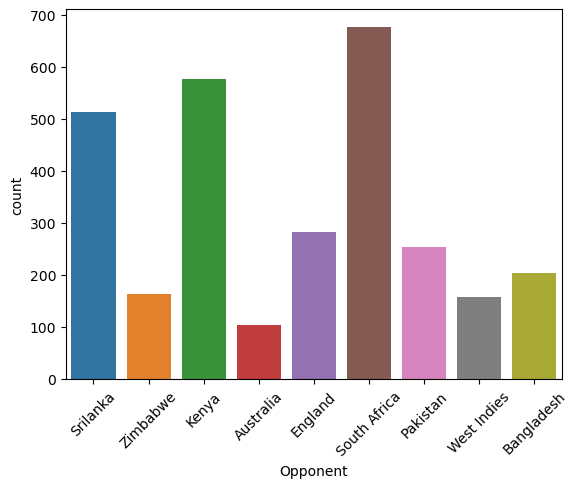

In [88]:
sns.countplot(x='Opponent', data=df)
plt.xticks(rotation=45)
plt.show()

In [89]:
df['Season'].value_counts()

Rainy     1371
Summer     918
Winter     641
Name: Season, dtype: int64

In [90]:
df['Season'].value_counts(normalize=True)* 100

Rainy     46.791809
Summer    31.331058
Winter    21.877133
Name: Season, dtype: float64

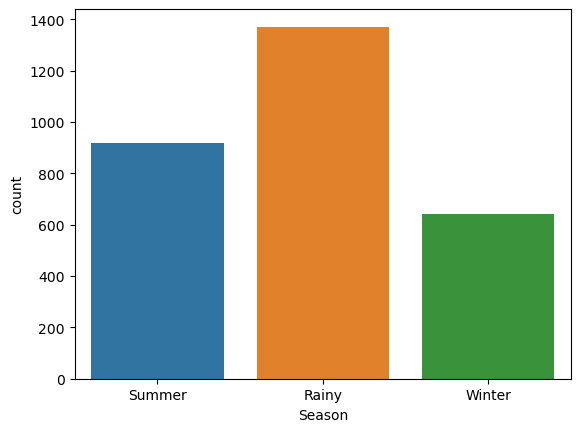

In [91]:
sns.countplot(x='Season', data=df)
plt.show()

In [92]:
df['Offshore'].value_counts()

No     2121
Yes     809
Name: Offshore, dtype: int64

In [93]:
df['Offshore'].value_counts(normalize=True)* 100

No     72.389078
Yes    27.610922
Name: Offshore, dtype: float64

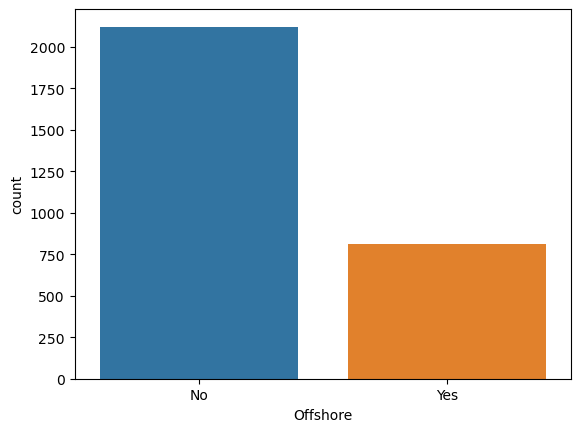

In [94]:
sns.countplot(x='Offshore', data=df)
plt.show()

### Bivariate analysis

#### Num vs Num

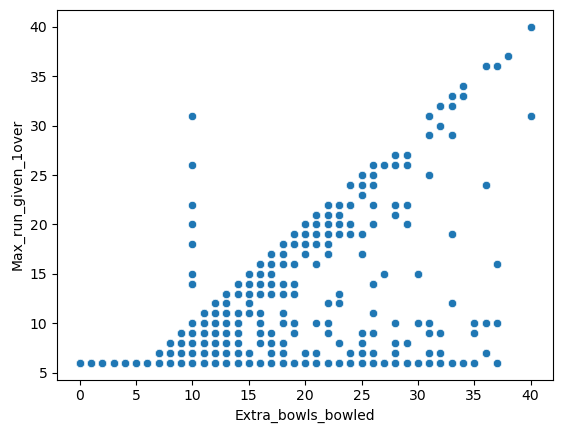

In [95]:
sns.scatterplot(x='Extra_bowls_bowled', y='Max_run_given_1over', data=df)
plt.show()

#### Cat vs Cat

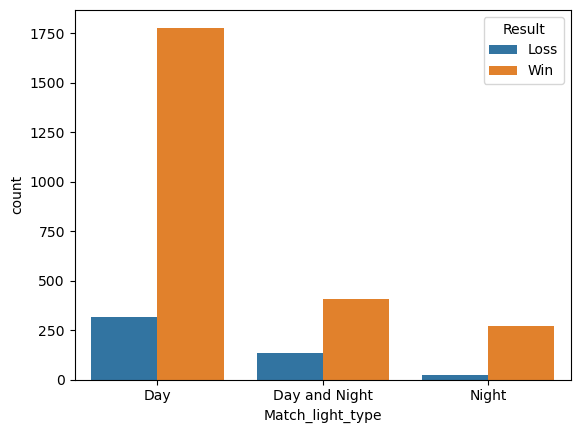

In [96]:
sns.countplot(x='Match_light_type', hue='Result', data=df)
plt.show;

In [97]:
pd.crosstab(df['Match_light_type'], df['Result'], normalize='index') * 100

Result,Loss,Win
Match_light_type,,
Day,15.002389,84.997611
Day and Night,24.953789,75.046211
Night,8.108108,91.891892


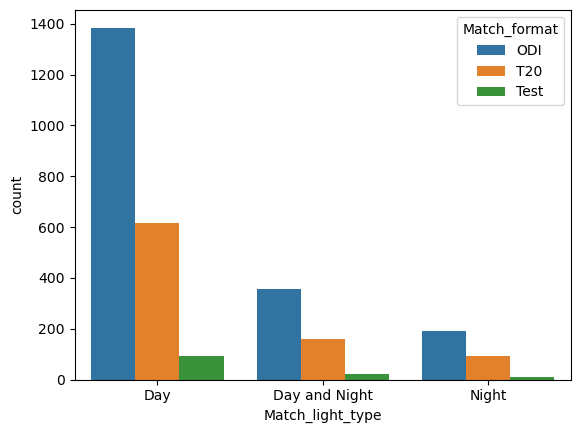

In [98]:
sns.countplot(x='Match_light_type', hue='Match_format', data=df)
plt.show;

In [99]:
pd.crosstab(df['Match_light_type'], df['Match_format'], normalize='index') * 100

Match_format,ODI,T20,Test
Match_light_type,,,
Day,66.172957,29.479216,4.347826
Day and Night,66.173752,29.759704,4.066543
Night,64.864865,31.081081,4.054054


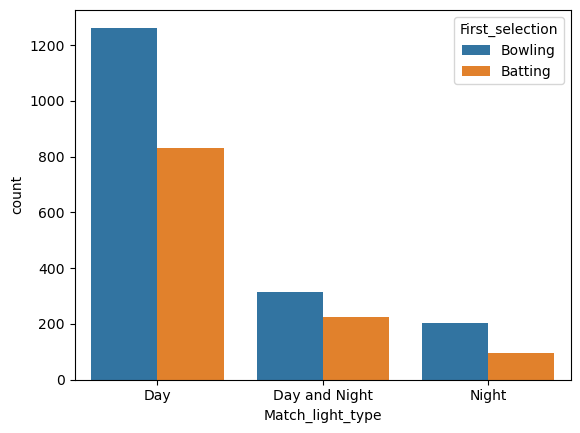

In [100]:
sns.countplot(x='Match_light_type', hue='First_selection', data=df)
plt.show;

In [101]:
pd.crosstab(df['Match_light_type'], df['First_selection'], normalize='index') * 100

First_selection,Batting,Bowling
Match_light_type,,
Day,39.655996,60.344004
Day and Night,41.589649,58.410351
Night,31.756757,68.243243


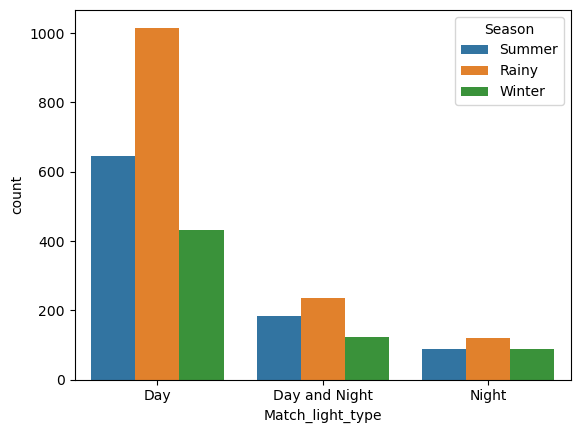

In [102]:
sns.countplot(x='Match_light_type', hue='Season', data=df)
plt.show;

In [103]:
pd.crosstab(df['Match_light_type'], df['Season'], normalize='index') * 100

Season,Rainy,Summer,Winter
Match_light_type,,,
Day,48.542762,30.817009,20.640229
Day and Night,43.438078,34.011091,22.550832
Night,40.540541,30.067568,29.391892


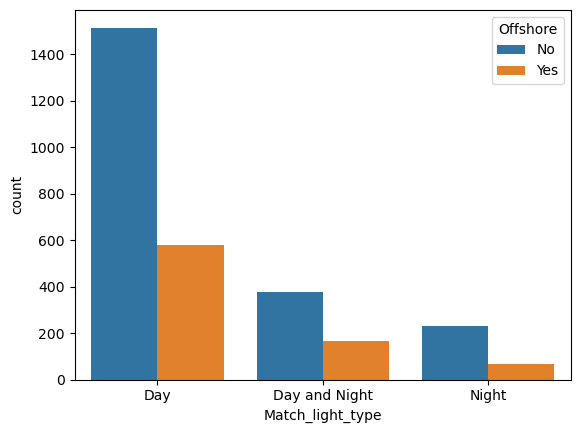

In [104]:
sns.countplot(x='Match_light_type', hue='Offshore', data=df)
plt.show;

In [105]:
pd.crosstab(df['Match_light_type'], df['Offshore'], normalize='index') * 100

Offshore,No,Yes
Match_light_type,,
Day,72.384138,27.615862
Day and Night,69.685767,30.314233
Night,77.364865,22.635135


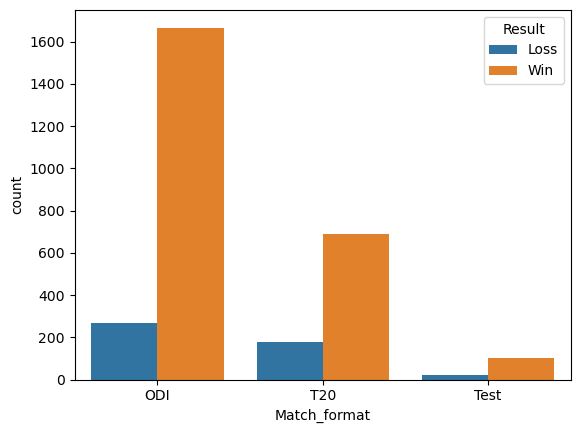

In [106]:
sns.countplot(x='Match_format', hue='Result', data=df)
plt.show;

In [107]:
pd.crosstab(df['Match_format'], df['Result'], normalize='index') * 100

Result,Loss,Win
Match_format,,
ODI,13.901809,86.098191
T20,20.689655,79.310345
Test,19.200000,80.800000


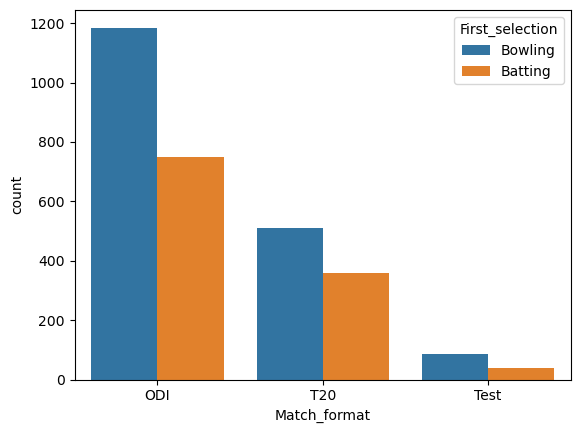

In [108]:
sns.countplot(x='Match_format', hue='First_selection', data=df)
plt.show;

In [109]:
pd.crosstab(df['Match_format'], df['First_selection'], normalize='index') * 100

First_selection,Batting,Bowling
Match_format,,
ODI,38.75969,61.24031
T20,41.37931,58.62069
Test,31.20000,68.80000


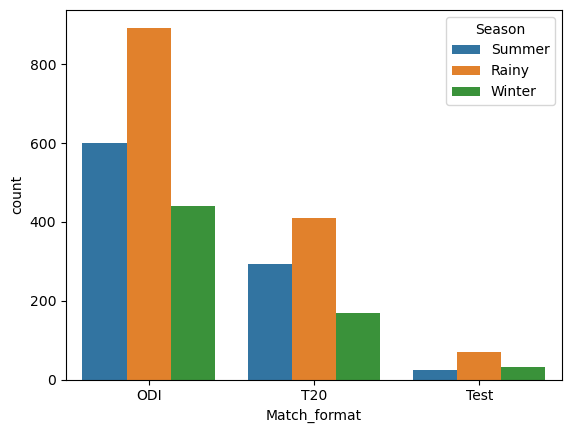

In [110]:
sns.countplot(x='Match_format', hue='Season', data=df)
plt.show()

In [111]:
pd.crosstab(df['Match_format'], df['Season'], normalize='index') * 100

Season,Rainy,Summer,Winter
Match_format,,,
ODI,46.149871,31.059432,22.790698
T20,47.011494,33.678161,19.310345
Test,55.200000,19.200000,25.600000


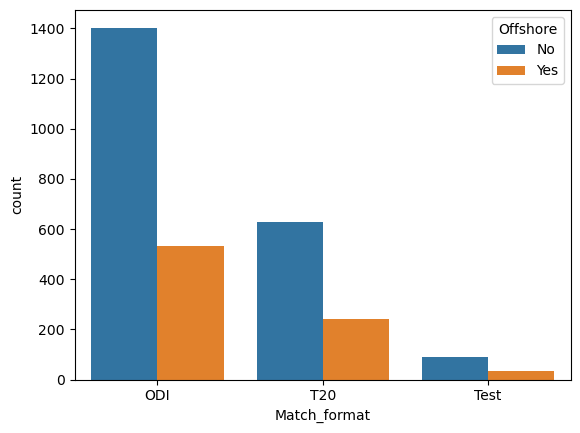

In [112]:
sns.countplot(x='Match_format', hue='Offshore', data=df)
plt.show()

In [113]:
pd.crosstab(df['Match_format'], df['Offshore'], normalize='index') * 100

Offshore,No,Yes
Match_format,,
ODI,72.506460,27.493540
T20,72.068966,27.931034
Test,72.800000,27.200000


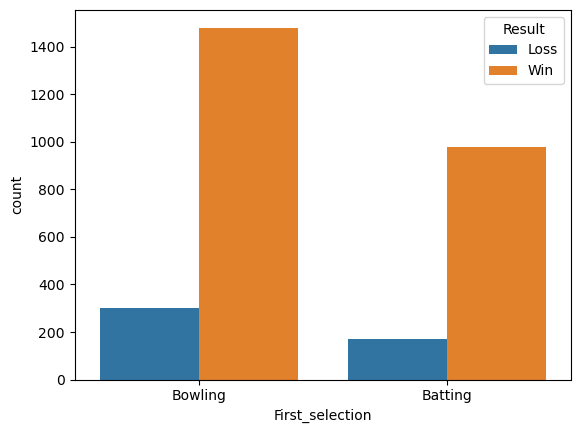

In [114]:
sns.countplot(x='First_selection', hue='Result', data=df)
plt.show()

In [115]:
pd.crosstab(df['First_selection'], df['Result'], normalize='index') * 100

Result,Loss,Win
First_selection,,
Batting,14.969539,85.030461
Bowling,16.900618,83.099382


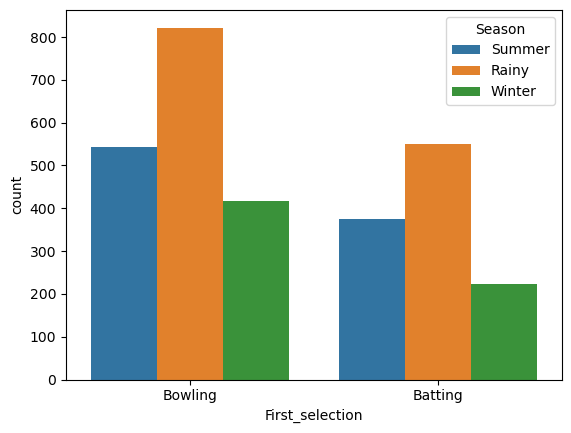

In [116]:
sns.countplot(x='First_selection', hue='Season', data=df)
plt.show()

In [117]:
pd.crosstab(df['First_selection'], df['Season'], normalize='index') * 100

Season,Rainy,Summer,Winter
First_selection,,,
Batting,47.780679,32.724108,19.495213
Bowling,46.153846,30.432341,23.413812


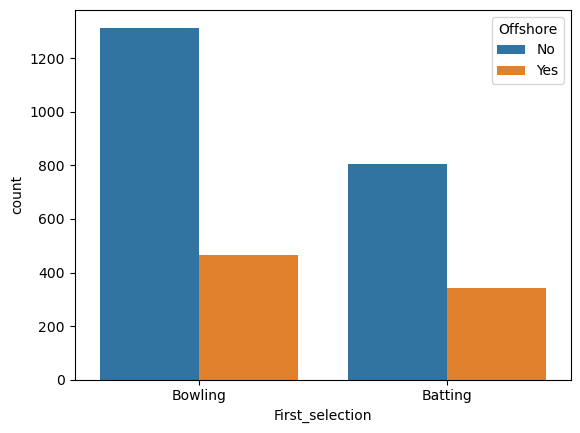

In [118]:
sns.countplot(x='First_selection', hue='Offshore', data=df)
plt.show()

In [119]:
pd.crosstab(df['First_selection'], df['Offshore'], normalize='index') * 100

Offshore,No,Yes
First_selection,,
Batting,70.147955,29.852045
Bowling,73.834924,26.165076


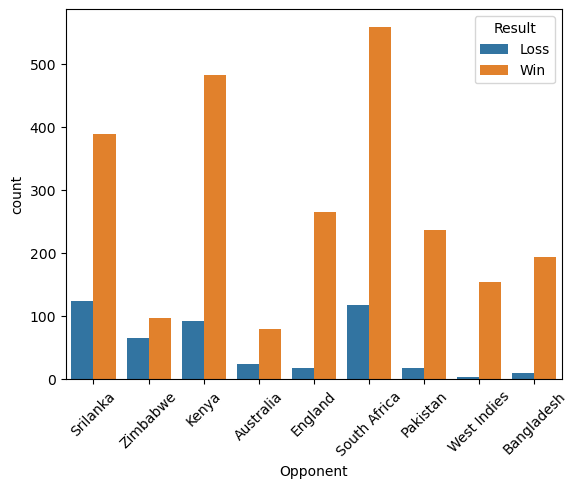

In [120]:
sns.countplot(x='Opponent', hue='Result', data=df)
plt.xticks(rotation=45)
plt.show()

In [121]:
pd.crosstab(df['Opponent'], df['Result'], normalize='index') * 100

Result,Loss,Win
Opponent,,
Australia,23.076923,76.923077
Bangladesh,4.901961,95.098039
England,6.360424,93.639576
Kenya,16.145833,83.854167
Pakistan,6.719368,93.280632
South Africa,17.307692,82.692308
Srilanka,24.171540,75.828460
West Indies,2.531646,97.468354
Zimbabwe,40.490798,59.509202


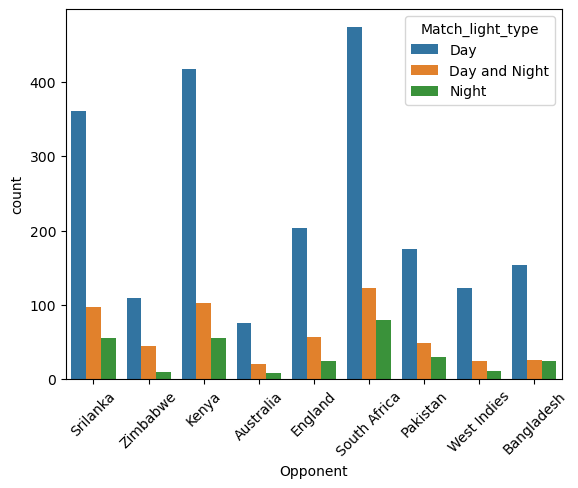

In [122]:
sns.countplot(x='Opponent', hue='Match_light_type', data=df)
plt.xticks(rotation=45)
plt.show()

In [123]:
pd.crosstab(df['Opponent'], df['Match_light_type'], normalize='index') * 100

Match_light_type,Day,Day and Night,Night
Opponent,,,
Australia,73.076923,19.230769,7.692308
Bangladesh,75.490196,12.745098,11.764706
England,71.731449,19.787986,8.480565
Kenya,72.569444,17.881944,9.548611
Pakistan,69.169960,18.972332,11.857708
South Africa,70.118343,18.195266,11.686391
Srilanka,70.370370,18.908382,10.721248
West Indies,77.848101,15.189873,6.962025
Zimbabwe,66.871166,26.993865,6.134969


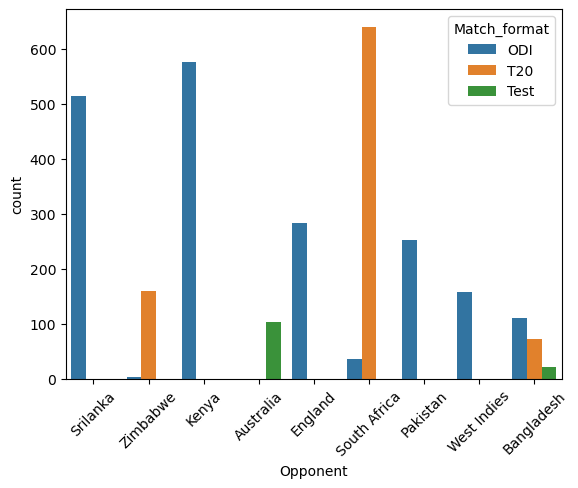

In [124]:
sns.countplot(x='Opponent', hue='Match_format', data=df)
plt.xticks(rotation=45)
plt.show()

In [125]:
pd.crosstab(df['Opponent'], df['Match_format'], normalize='index') * 100

Match_format,ODI,T20,Test
Opponent,,,
Australia,0.961538,0.000000,99.038462
Bangladesh,53.921569,35.294118,10.784314
England,100.000000,0.000000,0.000000
Kenya,100.000000,0.000000,0.000000
Pakistan,100.000000,0.000000,0.000000
South Africa,5.473373,94.526627,0.000000
Srilanka,100.000000,0.000000,0.000000
West Indies,100.000000,0.000000,0.000000
Zimbabwe,2.453988,97.546012,0.000000


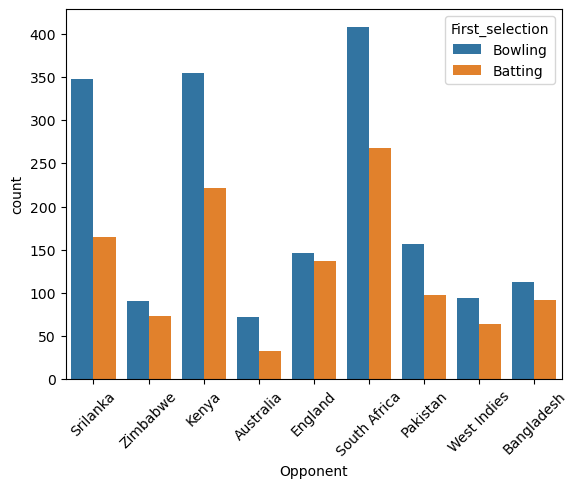

In [126]:
sns.countplot(x='Opponent', hue='First_selection', data=df)
plt.xticks(rotation=45)
plt.show()

In [127]:
pd.crosstab(df['Opponent'], df['First_selection'], normalize='index') * 100

First_selection,Batting,Bowling
Opponent,,
Australia,30.769231,69.230769
Bangladesh,45.098039,54.901961
England,48.409894,51.590106
Kenya,38.368056,61.631944
Pakistan,38.339921,61.660079
South Africa,39.644970,60.355030
Srilanka,32.163743,67.836257
West Indies,40.506329,59.493671
Zimbabwe,44.785276,55.214724


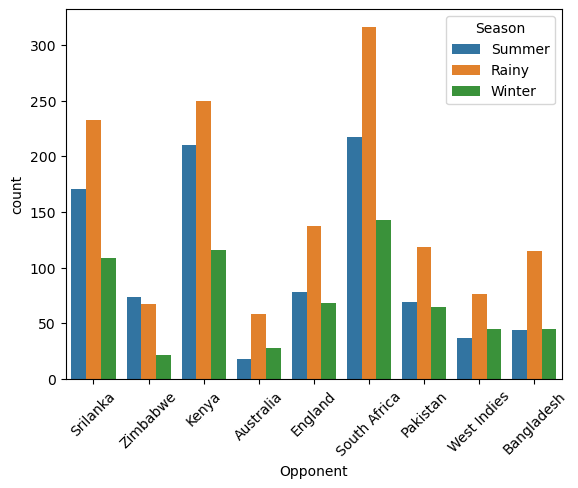

In [128]:
sns.countplot(x='Opponent', hue='Season', data=df)
plt.xticks(rotation=45)
plt.show()

In [129]:
pd.crosstab(df['Opponent'], df['Season'], normalize='index') * 100

Season,Rainy,Summer,Winter
Opponent,,,
Australia,55.769231,17.307692,26.923077
Bangladesh,56.372549,21.568627,22.058824
England,48.409894,27.561837,24.028269
Kenya,43.402778,36.458333,20.138889
Pakistan,47.035573,27.272727,25.691700
South Africa,46.745562,32.100592,21.153846
Srilanka,45.419103,33.333333,21.247563
West Indies,48.101266,23.417722,28.481013
Zimbabwe,41.104294,45.398773,13.496933


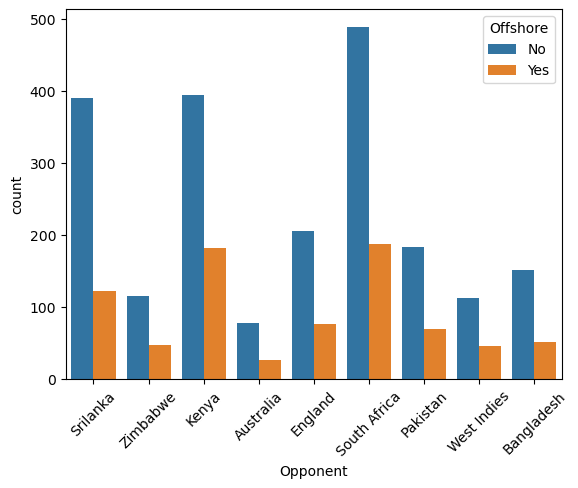

In [130]:
sns.countplot(x='Opponent', hue='Offshore', data=df)
plt.xticks(rotation=45)
plt.show()

In [131]:
pd.crosstab(df['Opponent'], df['Offshore'], normalize='index') * 100

Offshore,No,Yes
Opponent,,
Australia,75.000000,25.000000
Bangladesh,74.509804,25.490196
England,72.791519,27.208481
Kenya,68.402778,31.597222
Pakistan,72.332016,27.667984
South Africa,72.337278,27.662722
Srilanka,76.218324,23.781676
West Indies,70.886076,29.113924
Zimbabwe,71.165644,28.834356


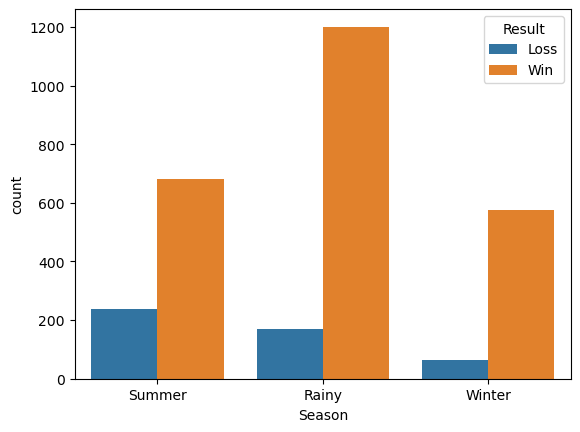

In [132]:
sns.countplot(x='Season', hue='Result', data=df)
plt.show()

In [133]:
pd.crosstab(df['Season'], df['Result'], normalize='index') * 100

Result,Loss,Win
Season,,
Rainy,12.399708,87.600292
Summer,25.925926,74.074074
Winter,10.140406,89.859594


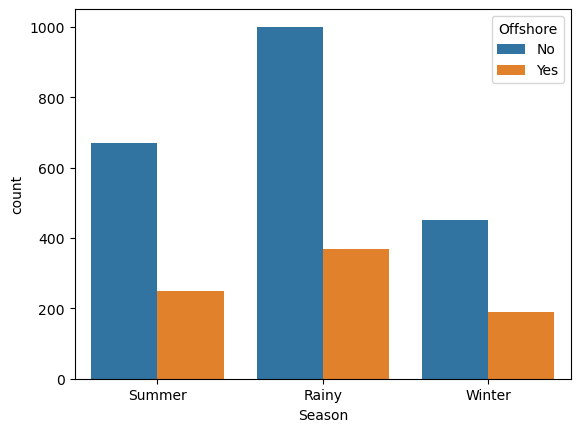

In [134]:
sns.countplot(x='Season', hue='Offshore', data=df)
plt.show()

In [135]:
pd.crosstab(df['Season'], df['Offshore'], normalize='index') * 100

Offshore,No,Yes
Season,,
Rainy,73.012400,26.987600
Summer,72.875817,27.124183
Winter,70.358814,29.641186


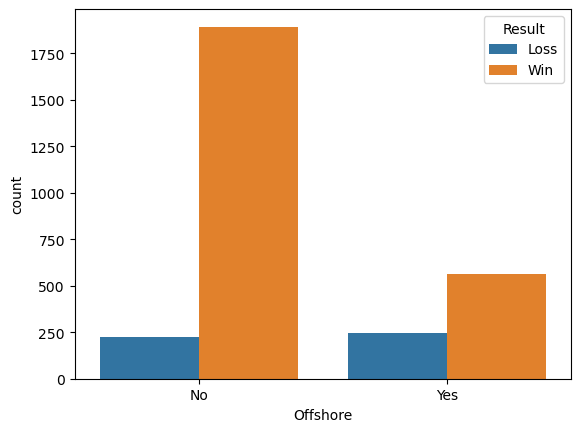

In [136]:
sns.countplot(x='Offshore', hue='Result', data=df)
plt.show()

In [137]:
pd.crosstab(df['Offshore'], df['Result'], normalize='index') * 100

Result,Loss,Win
Offshore,,
No,10.702499,89.297501
Yes,30.407911,69.592089


### Num vs Cat

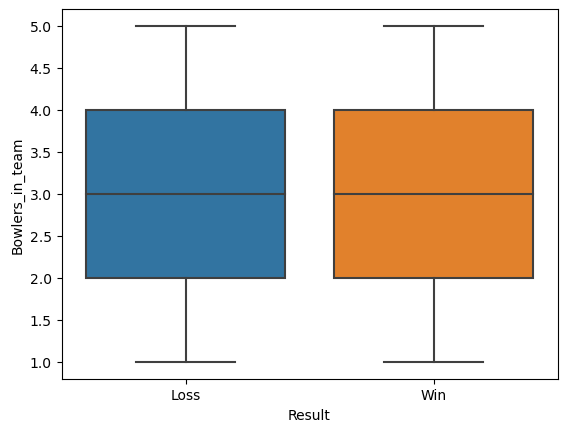

In [138]:
sns.boxplot(x='Result', y='Bowlers_in_team', data=df)
plt.show()

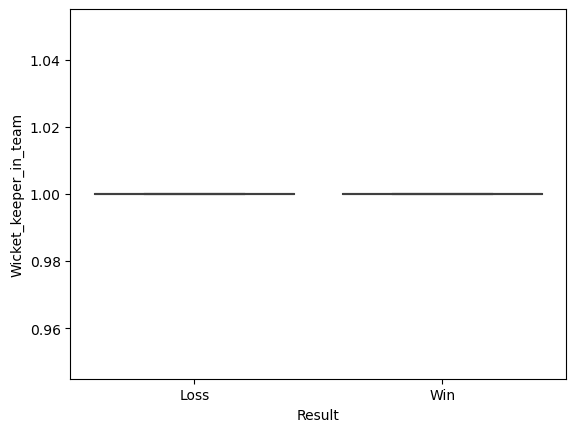

In [139]:
sns.boxplot(x='Result', y='Wicket_keeper_in_team', data=df)
plt.show()

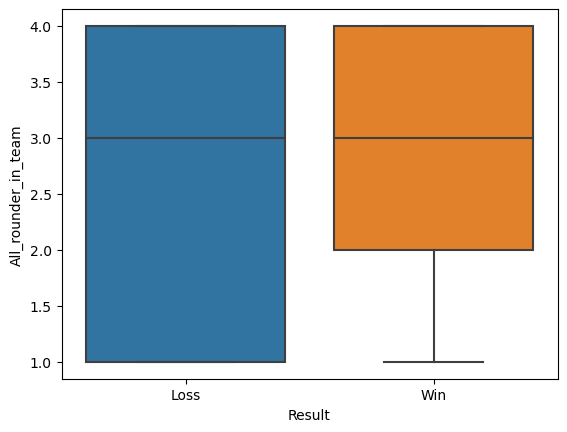

In [140]:
sns.boxplot(x='Result', y='All_rounder_in_team', data=df)
plt.show()

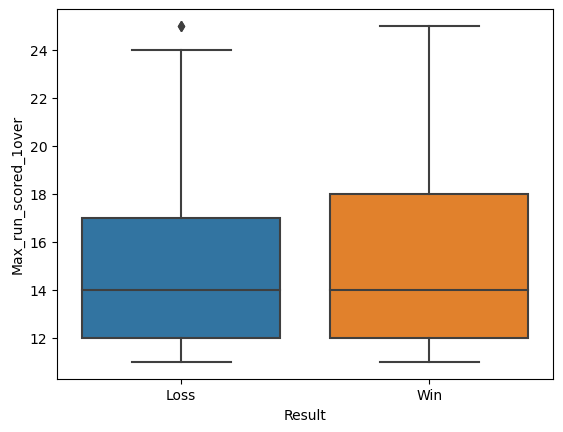

In [141]:
sns.boxplot(x='Result', y='Max_run_scored_1over', data=df)
plt.show()

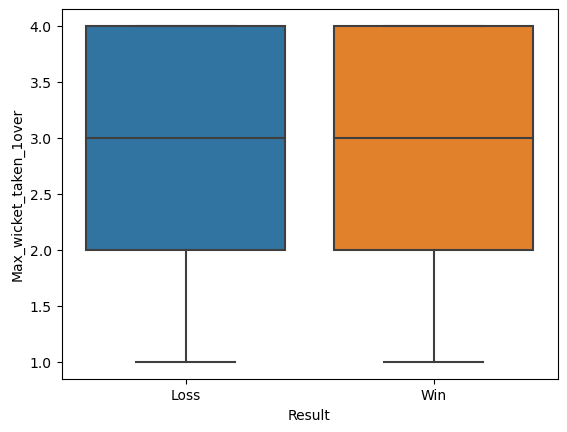

In [142]:
sns.boxplot(x='Result', y='Max_wicket_taken_1over', data=df)
plt.show()

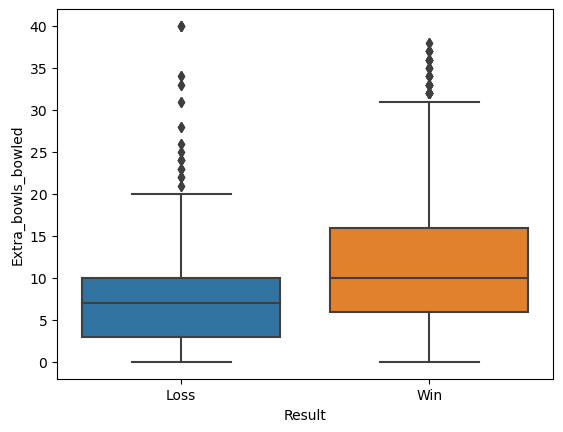

In [143]:
sns.boxplot(x='Result', y='Extra_bowls_bowled', data=df)
plt.show()

In [144]:
df.groupby('Result')['Extra_bowls_bowled'].describe()

,count,mean,std,min,25%,50%,75%,max
Result,,,,,,,,
Loss,473.0,8.194503,7.130459,0.0,3.0,7.0,10.0,40.0
Win,2457.0,11.826618,7.720276,0.0,6.0,10.0,16.0,38.0


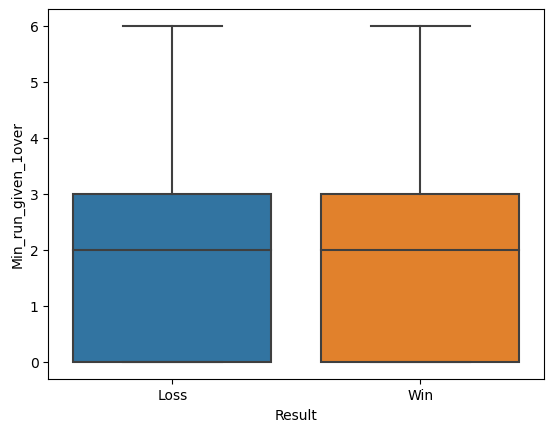

In [145]:
sns.boxplot(x='Result', y='Min_run_given_1over', data=df)
plt.show()

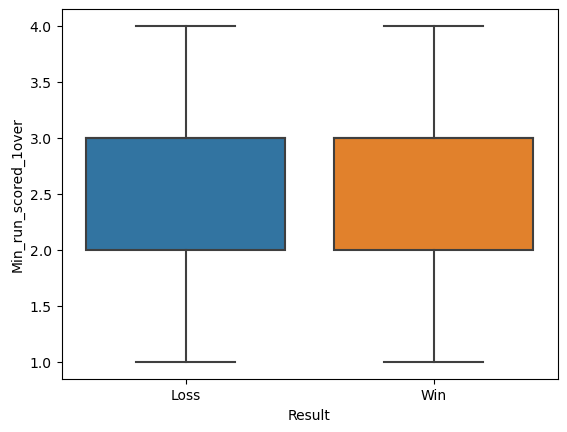

In [146]:
sns.boxplot(x='Result', y='Min_run_scored_1over', data=df)
plt.show()

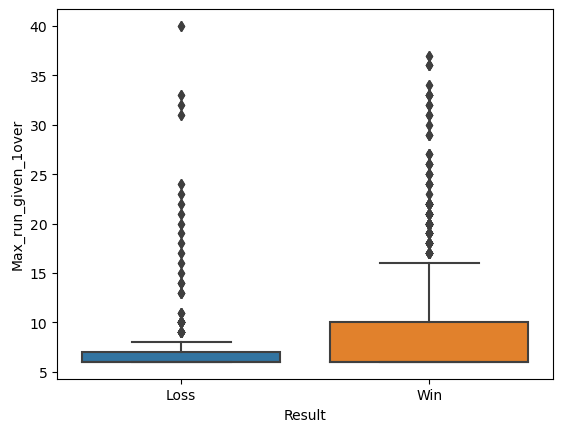

In [147]:
sns.boxplot(x='Result', y='Max_run_given_1over', data=df)
plt.show()

In [148]:
df.groupby('Result')['Max_run_given_1over'].describe()

,count,mean,std,min,25%,50%,75%,max
Result,,,,,,,,
Loss,473.0,7.739958,4.629267,6.0,6.0,6.0,7.0,40.0
Win,2457.0,8.811152,5.030298,6.0,6.0,6.0,10.0,37.0


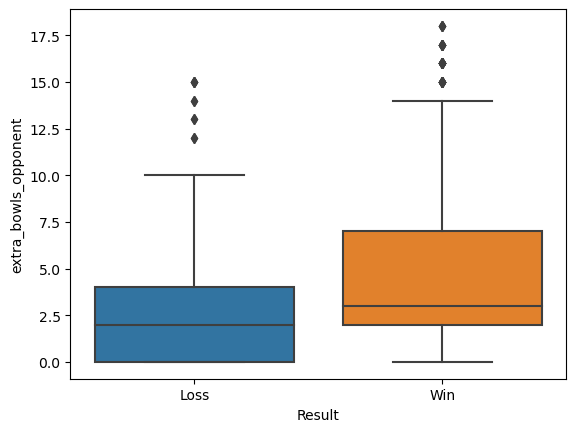

In [149]:
sns.boxplot(x='Result', y='extra_bowls_opponent', data=df)
plt.show()

In [150]:
df.groupby('Result')['extra_bowls_opponent'].describe()

,count,mean,std,min,25%,50%,75%,max
Result,,,,,,,,
Loss,473.0,2.904863,3.174554,0.0,0.0,2.0,4.0,15.0
Win,2457.0,4.484737,3.652543,0.0,2.0,3.0,7.0,18.0


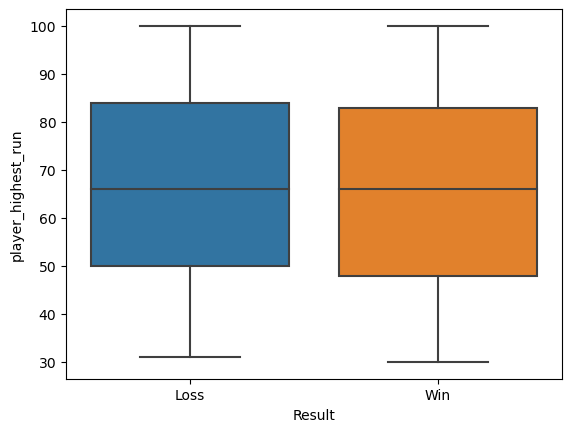

In [151]:
sns.boxplot(x='Result', y='player_highest_run', data=df)
plt.show()

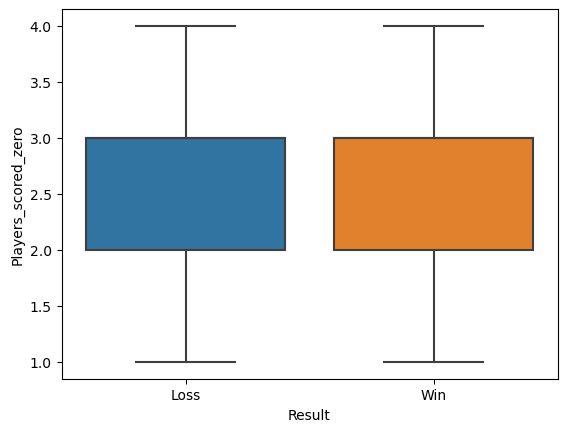

In [152]:
sns.boxplot(x='Result', y='Players_scored_zero', data=df)
plt.show()

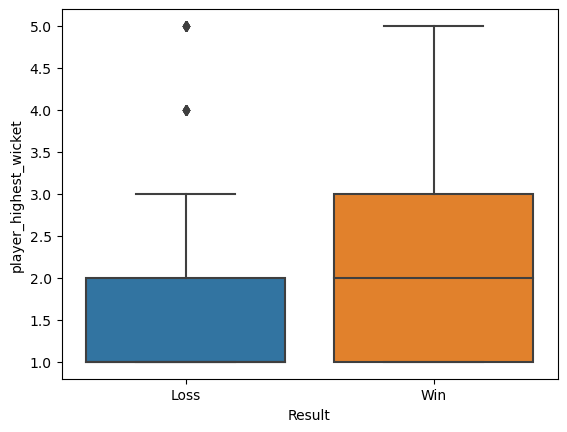

In [153]:
sns.boxplot(x='Result', y='player_highest_wicket', data=df)
plt.show()

In [154]:
df.groupby('Result')['player_highest_wicket'].describe()

,count,mean,std,min,25%,50%,75%,max
Result,,,,,,,,
Loss,473.0,1.634249,0.938495,1.0,1.0,1.0,2.0,5.0
Win,2457.0,2.146113,1.118497,1.0,1.0,2.0,3.0,5.0


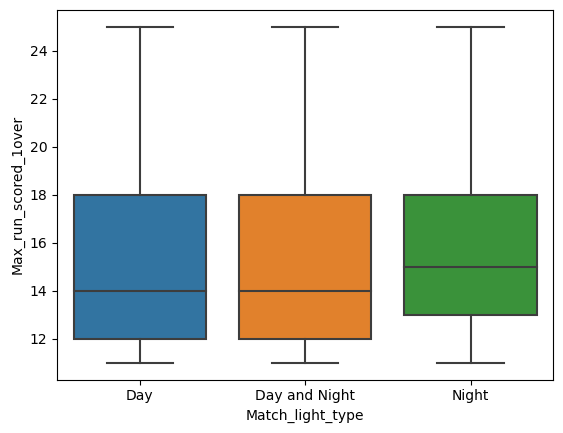

In [155]:
sns.boxplot(x='Match_light_type', y='Max_run_scored_1over', data=df)
plt.show()

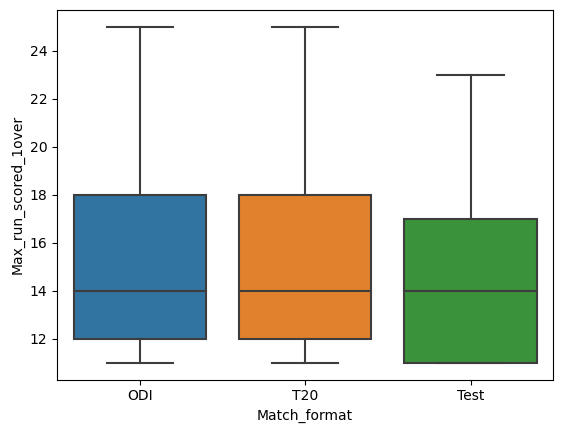

In [156]:
sns.boxplot(x='Match_format', y='Max_run_scored_1over', data=df)
plt.show()

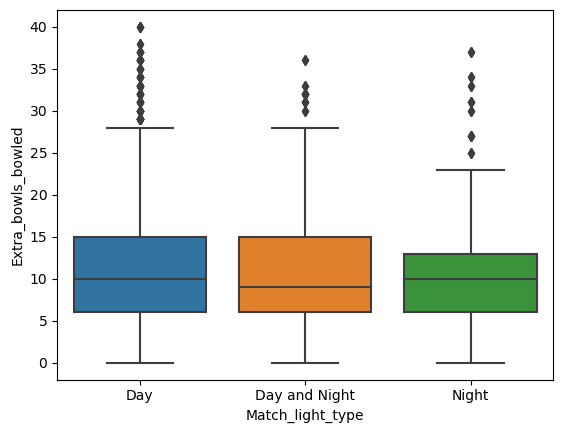

In [157]:
sns.boxplot(x='Match_light_type', y='Extra_bowls_bowled', data=df)
plt.show()

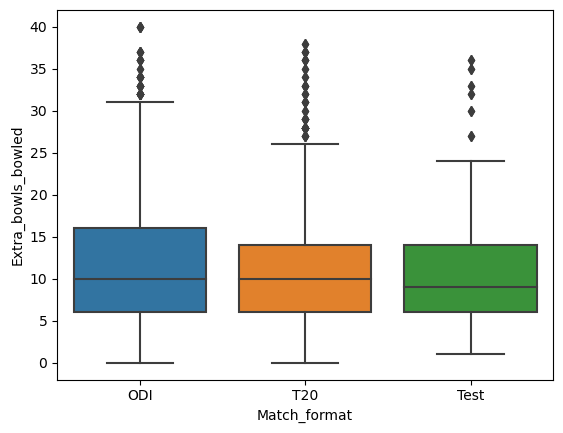

In [158]:
sns.boxplot(x='Match_format', y='Extra_bowls_bowled', data=df)
plt.show()

In [159]:
df.groupby('Match_format')['Extra_bowls_bowled'].describe()

,count,mean,std,min,25%,50%,75%,max
Match_format,,,,,,,,
ODI,1935.0,11.314212,7.751937,0.0,6.0,10.0,16.0,40.0
T20,870.0,11.037931,7.56451,0.0,6.0,10.0,14.0,38.0
Test,125.0,11.504,8.805812,1.0,6.0,9.0,14.0,36.0


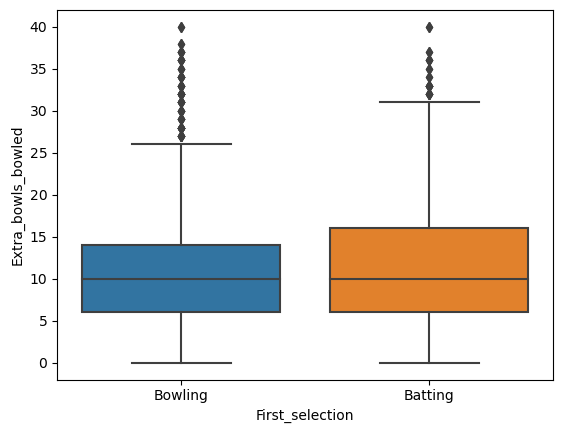

In [160]:
sns.boxplot(x='First_selection', y='Extra_bowls_bowled', data=df)
plt.show()

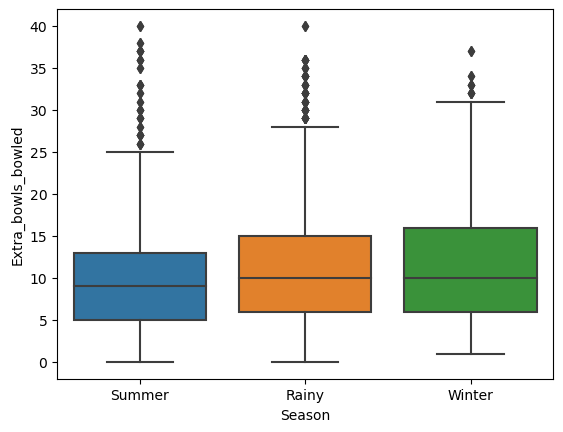

In [161]:
sns.boxplot(x='Season', y='Extra_bowls_bowled', data=df)
plt.show()

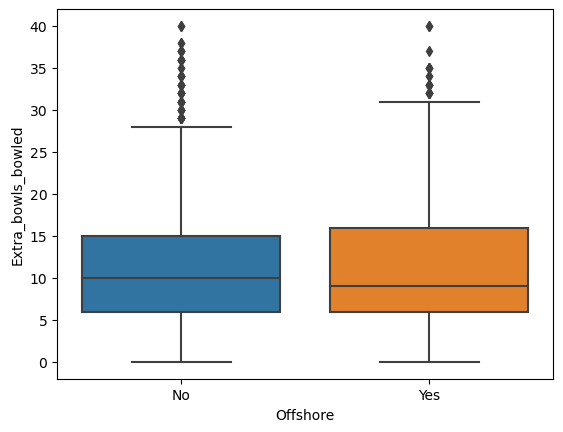

In [162]:
sns.boxplot(x='Offshore', y='Extra_bowls_bowled', data=df)
plt.show()

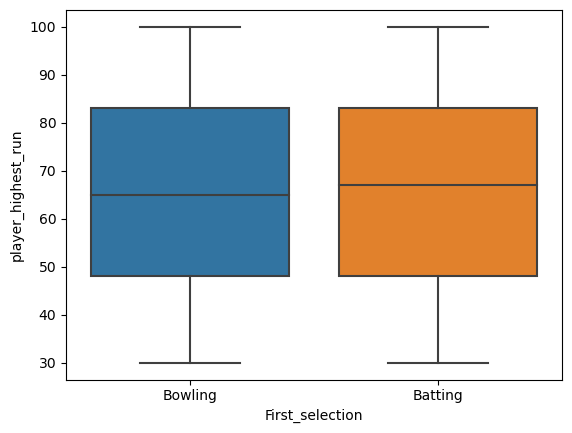

In [163]:
sns.boxplot(x='First_selection', y='player_highest_run', data=df)
plt.show()

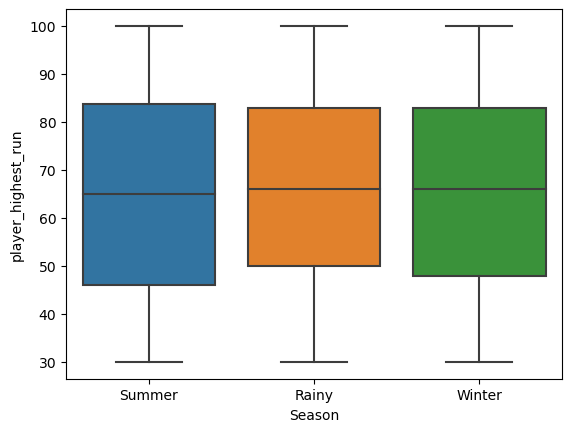

In [164]:
sns.boxplot(x='Season', y='player_highest_run', data=df)
plt.show()

### Multivariate analysis

C:\Users\Vasanth\AppData\Local\Temp\ipykernel_34056\3120797796.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(df.corr(), annot=True,fmt='.2f');


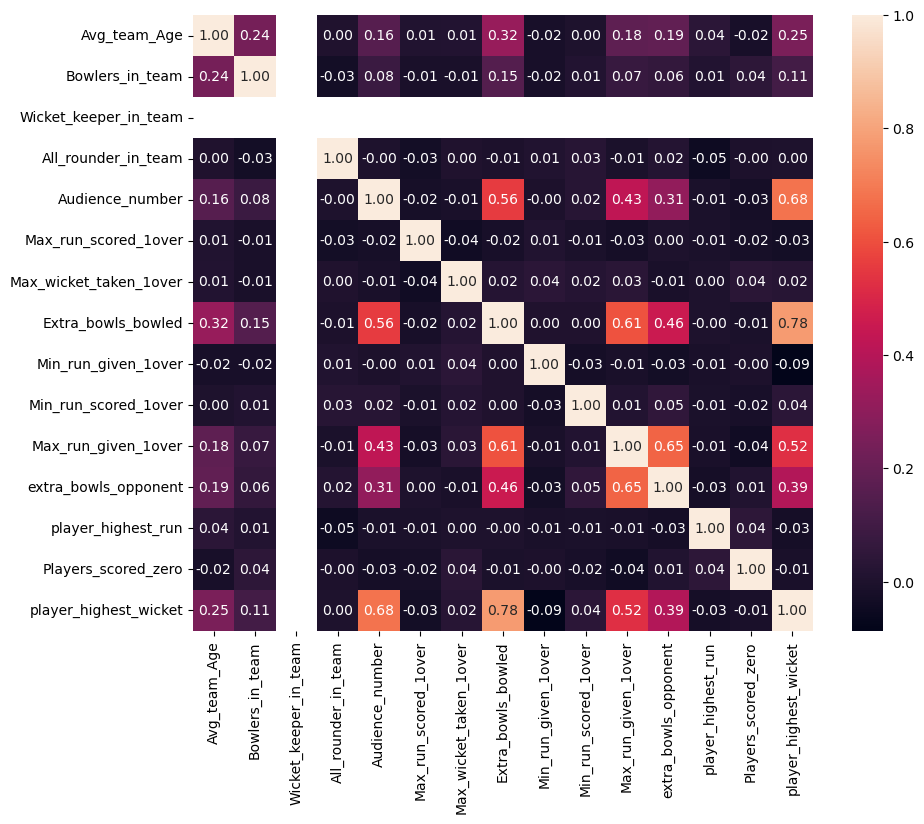

In [165]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True,fmt='.2f');

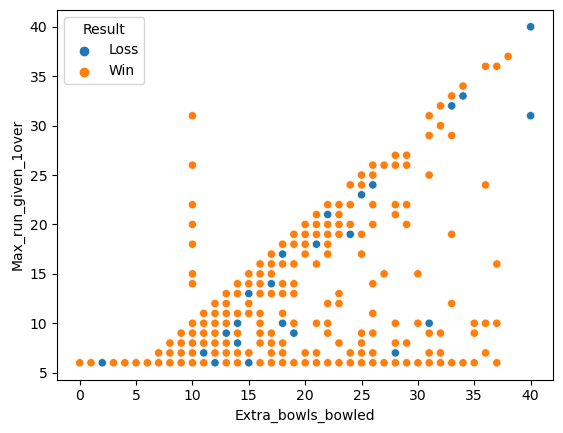

In [166]:
sns.scatterplot(x='Extra_bowls_bowled',y='Max_run_given_1over',hue='Result', data=df);

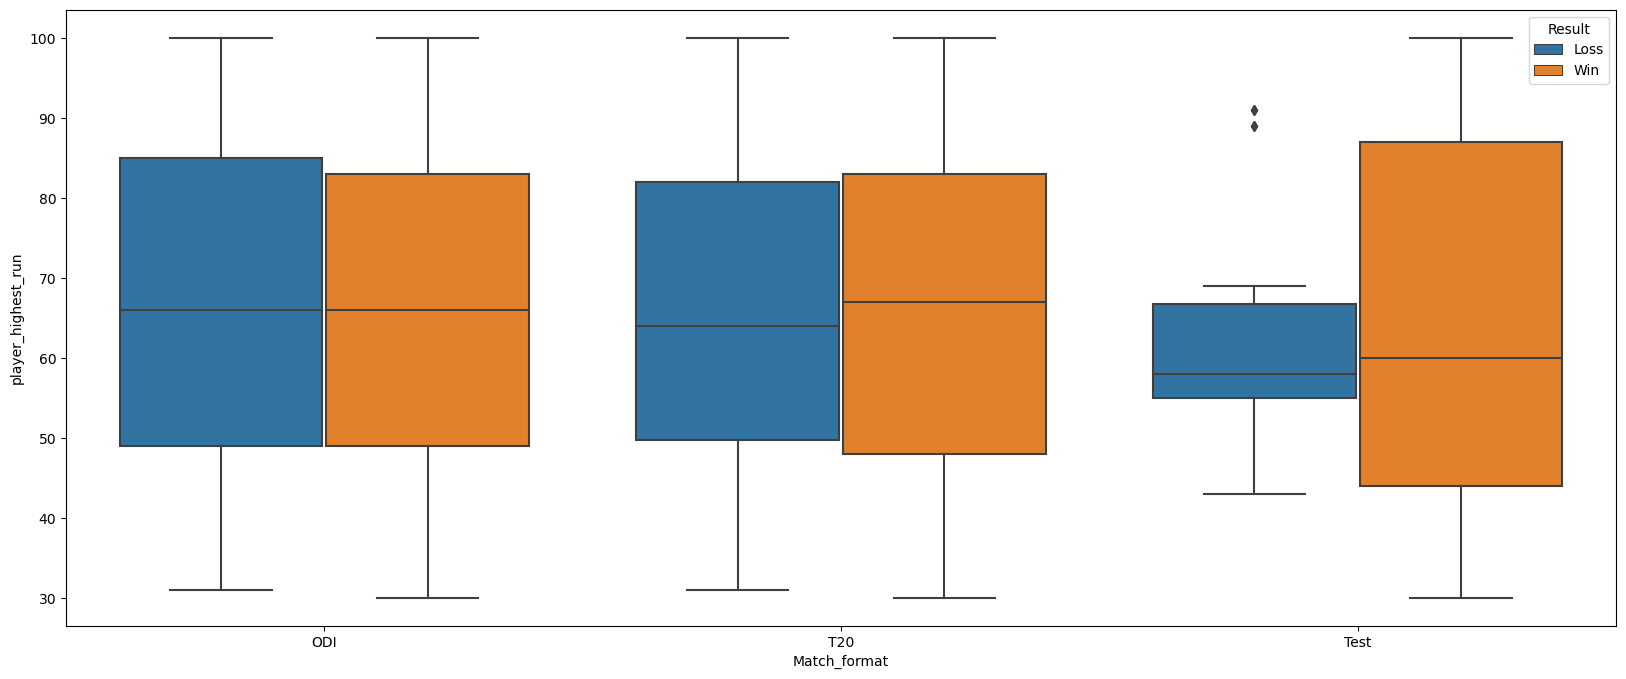

In [167]:
plt.figure(figsize=(20,8))
sns.boxplot(x='Match_format', y='player_highest_run', hue='Result', data=df);

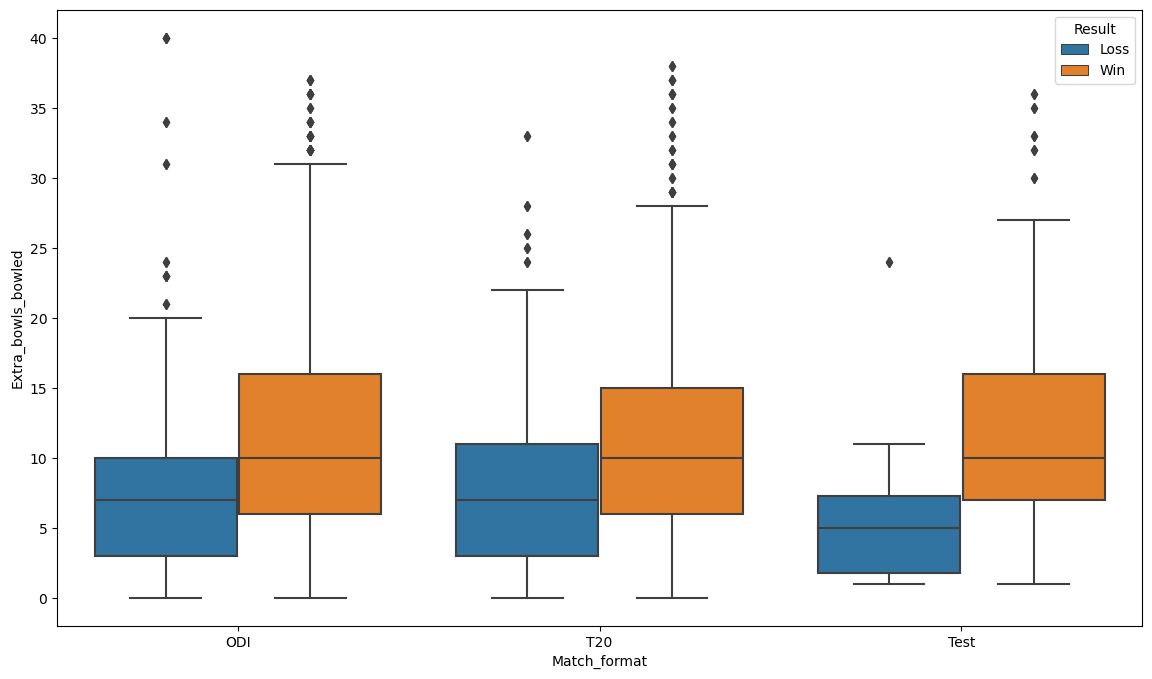

In [168]:
plt.figure(figsize=(14,8))
sns.boxplot(x='Match_format',y='Extra_bowls_bowled', hue='Result', data=df);

### Outlier Treatment

In [169]:
df[(df['Avg_team_Age']<20) | (df['Avg_team_Age']>40)]

,Avg_team_Age,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,Audience_number,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,...,Players_scored_zero,player_highest_wicket,Game_number,Result,Match_light_type,Match_format,First_selection,Opponent,Season,Offshore
0,18.0,3,1,3,9940.0,13,3,0,2,3,...,3,1,Game_1,Loss,Day,ODI,Bowling,Srilanka,Summer,No
58,17.0,1,1,1,15218.0,11,3,3,0,3,...,2,1,Game_59,Loss,Day and Night,T20,Batting,Zimbabwe,Summer,Yes
112,12.0,1,1,4,17304.0,23,1,1,2,3,...,3,1,Game_113,Loss,Day,ODI,Bowling,Kenya,Summer,Yes
770,70.0,4,1,3,15666.0,21,4,7,2,3,...,3,1,Game_771,Win,Day,ODI,Bowling,Srilanka,Rainy,No
831,69.0,4,1,3,30415.0,12,4,6,2,3,...,1,2,Game_832,Win,Night,ODI,Bowling,England,Rainy,No
899,70.0,3,1,1,36470.0,18,1,24,2,3,...,3,3,Game_900,Win,Day and Night,ODI,Bowling,Srilanka,Winter,No
975,50.0,3,1,3,42637.0,20,3,11,2,3,...,1,2,Game_976,Win,Day,ODI,Batting,England,Summer,No


In [170]:
df=df[(df['Avg_team_Age'] >=20) & (df['Avg_team_Age'] <=40)]

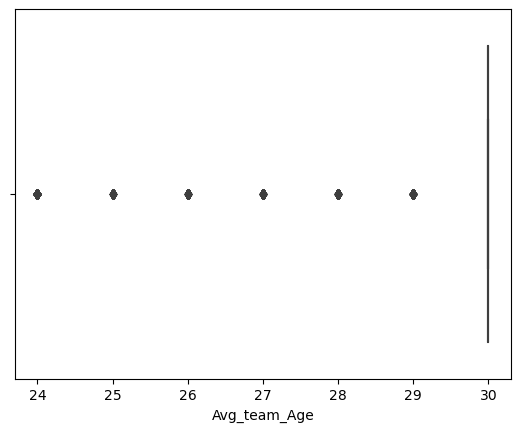

In [171]:
sns.boxplot(x='Avg_team_Age', data=df);

In [172]:
df['Avg_team_Age'].value_counts()

30.0    2300
24.0     184
29.0     131
27.0      92
28.0      92
26.0      74
25.0      50
Name: Avg_team_Age, dtype: int64

In [173]:
df['Avg_team_Age'].describe()

count    2923.000000
mean       29.233322
std         1.722230
min        24.000000
25%        30.000000
50%        30.000000
75%        30.000000
max        30.000000
Name: Avg_team_Age, dtype: float64

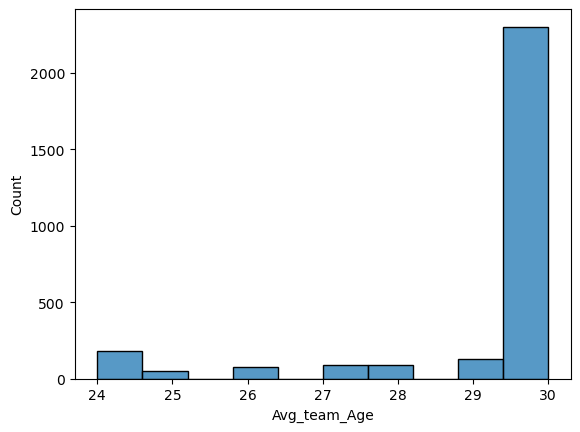

In [174]:
sns.histplot(df['Avg_team_Age'], bins=10);

### Segmentation

In [175]:
df.groupby('Result')[['Extra_bowls_bowled', 'player_highest_wicket', 'Max_run_given_1over', 'player_highest_run']].mean()

,Extra_bowls_bowled,player_highest_wicket,Max_run_given_1over,player_highest_run
Result,,,,
Loss,8.238298,1.638298,7.751064,65.580851
Win,11.826335,2.146351,8.808398,65.91276


In [176]:
df.groupby('Match_format')[['player_highest_run','Extra_bowls_bowled','Max_run_given_1over']].mean()

,player_highest_run,Extra_bowls_bowled,Max_run_given_1over
Match_format,,,
ODI,66.053396,11.324002,8.525143
T20,65.674338,11.047181,8.859609
Test,64.152,11.504,8.848


In [177]:
df.groupby('Match_light_type')[['player_highest_run','player_highest_wicket','Extra_bowls_bowled']].mean()

,player_highest_run,player_highest_wicket,Extra_bowls_bowled
Match_light_type,,,
Day,66.261369,2.078985,11.410244
Day and Night,64.994434,2.020408,11.014842
Night,64.59322,2.044068,10.538983


In [178]:
df.groupby('First_selection')[['player_highest_run','player_highest_wicket', 'Extra_bowls_bowled']].mean()

,player_highest_run,player_highest_wicket,Extra_bowls_bowled
First_selection,,,
Batting,66.079337,2.116827,11.708806
Bowling,65.717342,2.030968,10.952703


In [179]:
df.groupby('Season')[['player_highest_run','Extra_bowls_bowled','Max_run_given_1over','player_highest_wicket']].mean()

,player_highest_run,Extra_bowls_bowled,Max_run_given_1over,player_highest_wicket
Season,,,,
Rainy,66.511322,11.661066,8.808619,2.121987
Summer,64.989059,10.30744,8.271335,1.926696
Winter,65.707813,11.714063,8.798438,2.139063


In [180]:
df.groupby('Offshore')[['player_highest_run','Extra_bowls_bowled','Max_run_given_1over','player_highest_wicket']].mean()

,player_highest_run,Extra_bowls_bowled,Max_run_given_1over,player_highest_wicket
Offshore,,,,
No,65.95983,11.178166,8.63327,2.061909
Yes,65.596035,11.436183,8.651797,2.071871


### Clustering

In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2923 entries, 1 to 2929
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Avg_team_Age            2923 non-null   float64
 1   Bowlers_in_team         2923 non-null   Int64  
 2   Wicket_keeper_in_team   2923 non-null   Int64  
 3   All_rounder_in_team     2923 non-null   Int64  
 4   Audience_number         2923 non-null   float64
 5   Max_run_scored_1over    2923 non-null   Int64  
 6   Max_wicket_taken_1over  2923 non-null   Int64  
 7   Extra_bowls_bowled      2923 non-null   Int64  
 8   Min_run_given_1over     2923 non-null   Int64  
 9   Min_run_scored_1over    2923 non-null   Int64  
 10  Max_run_given_1over     2923 non-null   Int64  
 11  extra_bowls_opponent    2923 non-null   Int64  
 12  player_highest_run      2923 non-null   Int64  
 13  Players_scored_zero     2923 non-null   Int64  
 14  player_highest_wicket   2923 non-null   

In [182]:
df.describe()

,Avg_team_Age,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,Audience_number,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
count,2923.000000,2923.0,2923.0,2923.0,2.923000e+03,2923.0,2923.0,2923.0,2923.0,2923.0,2923.0,2923.0,2923.0,2923.0,2923.0
mean,29.233322,2.916524,1.0,2.726651,4.599112e+04,15.1844,2.713992,11.249401,1.95313,2.764283,8.638385,4.233322,65.859391,2.731098,2.06466
std,1.722230,1.009136,0.0,1.085748,4.800471e+04,3.642269,1.080424,7.741264,1.679952,0.703611,4.979038,3.626603,20.223031,0.709919,1.10793
min,24.000000,1.0,1.0,1.0,7.063000e+03,11.0,1.0,0.0,0.0,1.0,6.0,0.0,30.0,1.0,1.0
25%,30.000000,2.0,1.0,2.0,2.067100e+04,12.0,2.0,6.0,0.0,2.0,6.0,2.0,48.0,2.0,1.0
50%,30.000000,3.0,1.0,3.0,3.434900e+04,14.0,3.0,10.0,2.0,3.0,6.0,3.0,66.0,3.0,2.0
75%,30.000000,4.0,1.0,4.0,5.599650e+04,18.0,4.0,15.0,3.0,3.0,9.0,7.0,83.0,3.0,3.0
max,30.000000,5.0,1.0,4.0,1.399930e+06,25.0,4.0,40.0,6.0,4.0,40.0,18.0,100.0,4.0,5.0


In [183]:
df.duplicated().sum()

0

In [184]:
df_kmeans = df.drop(columns=['Game_number', 'Audience_number', 'Wicket_keeper_in_team'])

In [185]:
cat=[]
num=[]
for i in df_kmeans.columns:
    if df_kmeans[i].dtype=='object':
        cat.append(i)
    else:
        num.append(i)
print(cat)
print(num)

['Result', 'Match_light_type', 'Match_format', 'First_selection', 'Opponent', 'Season', 'Offshore']
['Avg_team_Age', 'Bowlers_in_team', 'All_rounder_in_team', 'Max_run_scored_1over', 'Max_wicket_taken_1over', 'Extra_bowls_bowled', 'Min_run_given_1over', 'Min_run_scored_1over', 'Max_run_given_1over', 'extra_bowls_opponent', 'player_highest_run', 'Players_scored_zero', 'player_highest_wicket']


In [186]:
features = [
    'Extra_bowls_bowled',
    'player_highest_run',
    'player_highest_wicket',
    'Max_run_given_1over',
    'Min_run_given_1over',  
    'Min_run_scored_1over'
]

In [187]:
X= df_kmeans[features]

In [188]:
scaler = StandardScaler()
X_scaled= scaler.fit_transform(X)

In [189]:
wss =[]

In [190]:
for i in range(1,11):
    KM =KMeans(n_clusters=i)
    KM.fit(X_scaled)
    wss.append(KM.inertia_)

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super

In [191]:
wss

[17538.000000000004,
 12939.579167155169,
 11107.706169600457,
 9790.126387137865,
 8777.528890739983,
 7830.924338050258,
 7344.937035182463,
 6961.816427185185,
 6565.824110023317,
 6264.711637845514]

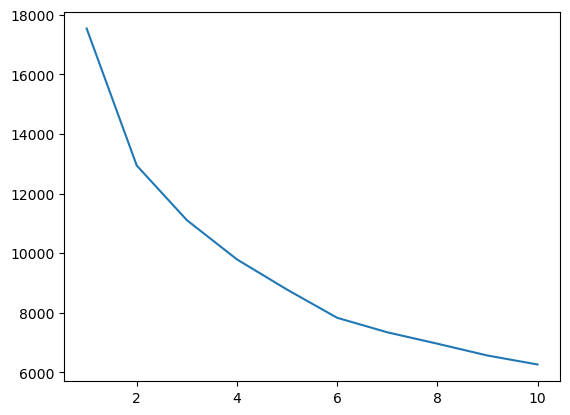

In [192]:
plt.plot(range(1,11), wss)

In [193]:
k_means =KMeans(n_clusters =3)
k_means.fit(X_scaled)
labels = k_means.labels_

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [194]:
df_profile = df_kmeans.copy()
df_profile['Cluster']= labels
df_profile.head(10)

,Avg_team_Age,Bowlers_in_team,All_rounder_in_team,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,...,Players_scored_zero,player_highest_wicket,Result,Match_light_type,Match_format,First_selection,Opponent,Season,Offshore,Cluster
1,24.0,3,4,12,1,0,0,3,6,0,...,2,1,Win,Day,T20,Batting,Zimbabwe,Summer,No,2
2,24.0,3,2,14,4,0,0,3,6,0,...,3,1,Loss,Day and Night,T20,Bowling,Zimbabwe,Rainy,Yes,2
3,24.0,2,2,15,4,0,2,3,6,0,...,3,1,Win,Day,ODI,Bowling,Kenya,Summer,No,2
4,24.0,1,3,12,4,0,0,3,6,0,...,3,1,Loss,Night,ODI,Bowling,Srilanka,Summer,No,2
5,24.0,3,4,15,3,0,5,4,6,0,...,3,1,Win,Night,ODI,Batting,Srilanka,Summer,No,2
6,24.0,2,2,12,3,0,0,4,6,0,...,3,1,Loss,Day and Night,T20,Batting,Zimbabwe,Summer,Yes,2
7,24.0,3,2,16,3,0,4,1,6,0,...,3,1,Win,Night,ODI,Batting,Kenya,Summer,No,1
8,24.0,3,3,13,3,0,2,3,6,0,...,3,1,Loss,Day,ODI,Bowling,Srilanka,Summer,No,1
9,24.0,3,4,12,1,0,0,3,6,0,...,2,1,Win,Day,T20,Batting,Zimbabwe,Summer,No,2
10,24.0,3,2,14,4,0,0,3,6,0,...,3,1,Loss,Day and Night,T20,Bowling,Zimbabwe,Summer,Yes,2


In [195]:
df_profile.to_excel('km.xlsx', index=False)

In [196]:
df_profile.groupby('Cluster').mean().T

C:\Users\Vasanth\AppData\Local\Temp\ipykernel_34056\2044318388.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_profile.groupby('Cluster').mean().T


Cluster,0,1,2
Avg_team_Age,30.0,29.016598,29.140765
Bowlers_in_team,3.030675,2.889627,2.897478
All_rounder_in_team,2.752556,2.73112,2.711961
Max_run_scored_1over,15.002045,15.305394,15.138324
Max_wicket_taken_1over,2.756646,2.707884,2.703011
Extra_bowls_bowled,24.803681,8.707884,8.348251
Min_run_given_1over,2.010225,1.921162,1.961758
Min_run_scored_1over,2.758691,2.819917,2.711961
Max_run_given_1over,15.654397,7.40332,7.057771
extra_bowls_opponent,7.302658,3.905394,3.333605


In [197]:
cls_export = df_profile.groupby('Cluster').mean().T
cls_export.to_excel('cls_export.xlsx')

C:\Users\Vasanth\AppData\Local\Temp\ipykernel_34056\2020752980.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  cls_export = df_profile.groupby('Cluster').mean().T


In [198]:
pd.crosstab(df_profile['Cluster'], df_profile['Result'], normalize='index') * 100

Result,Loss,Win
Cluster,,
0,7.361963,92.638037
1,18.091286,81.908714
2,17.575264,82.424736


In [199]:
cr = pd.crosstab(df_profile['Cluster'], df_profile['Result'], normalize='index') * 100
cr.to_excel('cr.xlsx')

In [200]:
df_profile.groupby('Cluster')['Match_light_type'].value_counts(normalize=True) * 100

Cluster  Match_light_type
0        Day                 73.415133
         Day and Night       18.404908
         Night                8.179959
1        Day                 69.958506
         Day and Night       19.336100
         Night               10.705394
2        Day                 72.172498
         Day and Night       17.575264
         Night               10.252238
Name: Match_light_type, dtype: float64

In [201]:
df_profile.groupby('Cluster')['Match_format'].value_counts(normalize=True) * 100

Cluster  Match_format
0        ODI             68.302658
         T20             26.789366
         Test             4.907975
1        ODI             63.651452
         T20             31.120332
         Test             5.228216
2        ODI             67.371847
         T20             29.536208
         Test             3.091945
Name: Match_format, dtype: float64

In [202]:
df_profile.groupby('Cluster')['First_selection'].value_counts(normalize=True) * 100

Cluster  First_selection
0        Bowling            55.623722
         Batting            44.376278
1        Bowling            63.402490
         Batting            36.597510
2        Bowling            60.211554
         Batting            39.788446
Name: First_selection, dtype: float64

In [203]:
df_profile.groupby('Cluster')['Opponent'].value_counts(normalize=True) * 100

Cluster  Opponent    
0        Bangladesh      36.196319
         West Indies     22.290389
         South Africa    14.928425
         England         10.838446
         Pakistan        10.633947
         Kenya            3.271984
         Srilanka         1.431493
         Australia        0.408998
1        South Africa    26.307054
         Kenya           20.082988
         Srilanka        20.000000
         England         10.373444
         Pakistan         7.883817
         Zimbabwe         6.556017
         Australia        5.311203
         West Indies      2.323651
         Bangladesh       1.161826
2        Kenya           25.793328
         South Africa    23.270952
         Srilanka        21.318145
         Pakistan         8.624898
         England          8.380797
         Zimbabwe         6.753458
         Australia        3.091945
         West Indies      1.708706
         Bangladesh       1.057771
Name: Opponent, dtype: float64

In [204]:
df_profile.groupby('Cluster')['Season'].value_counts(normalize=True) * 100

Cluster  Season
0        Rainy     52.556237
         Summer    24.539877
         Winter    22.903885
1        Rainy     44.564315
         Summer    33.609959
         Winter    21.825726
2        Rainy     46.786005
         Summer    31.651749
         Winter    21.562246
Name: Season, dtype: float64

In [205]:
df_profile.groupby('Cluster')['Offshore'].value_counts(normalize=True) * 100

Cluster  Offshore
0        No          69.938650
         Yes         30.061350
1        No          74.273859
         Yes         25.726141
2        No          71.521562
         Yes         28.478438
Name: Offshore, dtype: float64

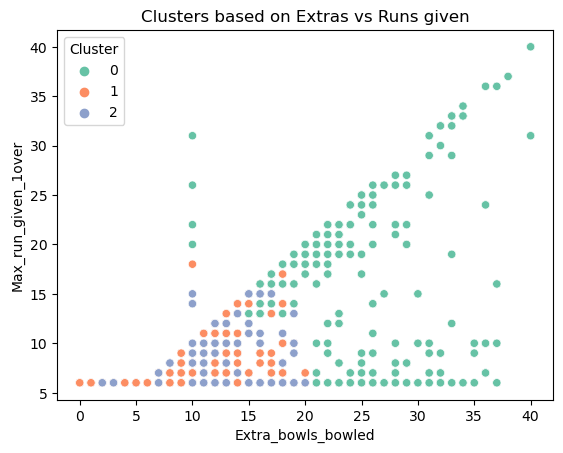

In [206]:
sns.scatterplot(x='Extra_bowls_bowled', y='Max_run_given_1over', hue='Cluster', data=df_profile, palette='Set2')
plt.title('Clusters based on Extras vs Runs given');

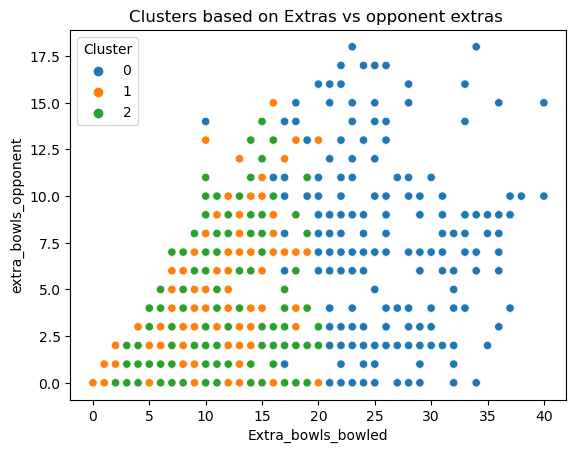

In [207]:
sns.scatterplot(x='Extra_bowls_bowled', y='extra_bowls_opponent', hue='Cluster', data=df_profile, palette='tab10')
plt.title('Clusters based on Extras vs opponent extras ');

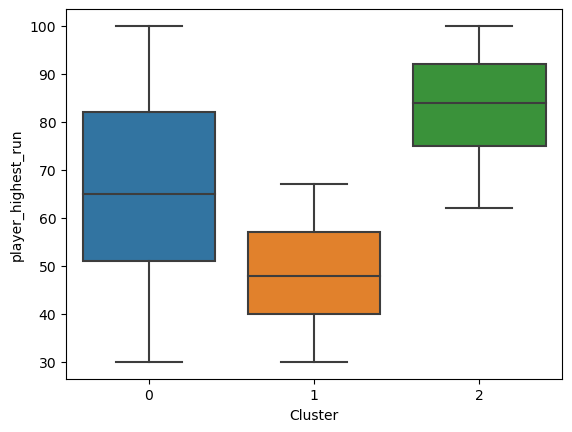

In [208]:
sns.boxplot(x='Cluster', y='player_highest_run', data=df_profile);

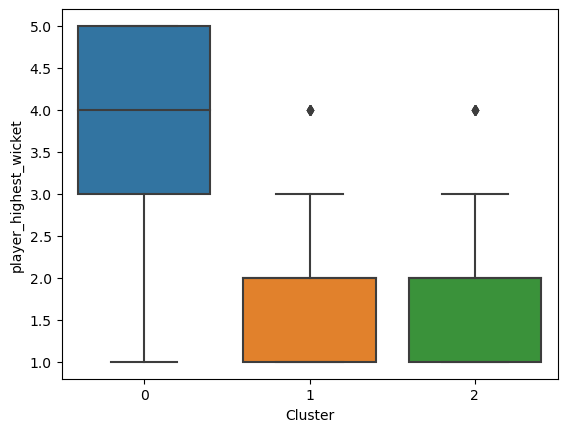

In [209]:
sns.boxplot(x='Cluster', y='player_highest_wicket', data=df_profile);

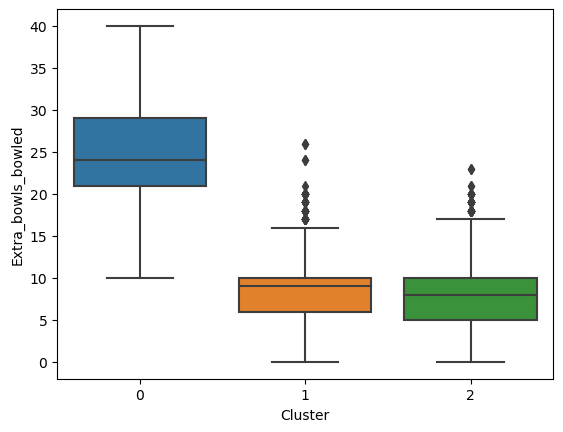

In [210]:
sns.boxplot(x='Cluster', y='Extra_bowls_bowled', data=df_profile);

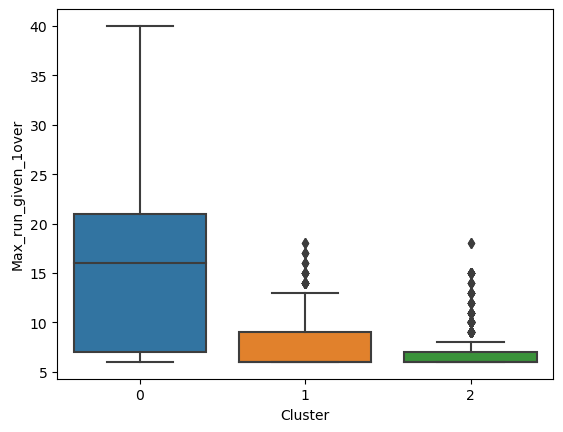

In [211]:
sns.boxplot(x='Cluster', y='Max_run_given_1over', data=df_profile);

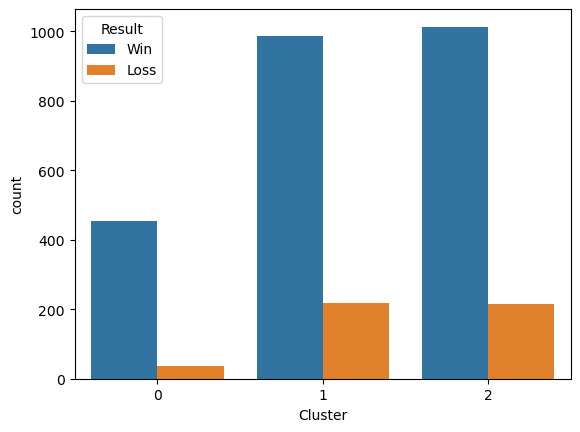

In [212]:
sns.countplot(x='Cluster', hue='Result', data=df_profile);

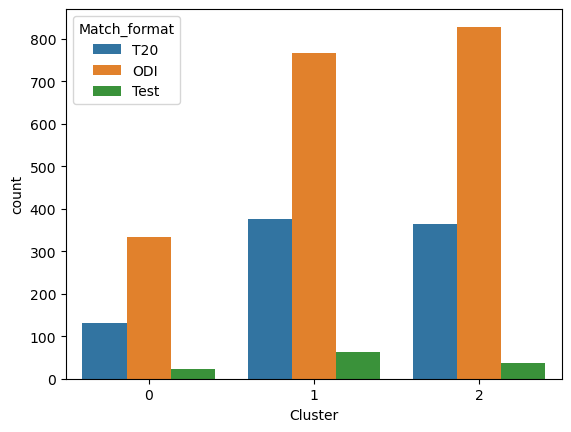

In [213]:
sns.countplot(x='Cluster', hue='Match_format', data=df_profile);

In [214]:
df_profile.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2923 entries, 1 to 2929
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Avg_team_Age            2923 non-null   float64
 1   Bowlers_in_team         2923 non-null   Int64  
 2   All_rounder_in_team     2923 non-null   Int64  
 3   Max_run_scored_1over    2923 non-null   Int64  
 4   Max_wicket_taken_1over  2923 non-null   Int64  
 5   Extra_bowls_bowled      2923 non-null   Int64  
 6   Min_run_given_1over     2923 non-null   Int64  
 7   Min_run_scored_1over    2923 non-null   Int64  
 8   Max_run_given_1over     2923 non-null   Int64  
 9   extra_bowls_opponent    2923 non-null   Int64  
 10  player_highest_run      2923 non-null   Int64  
 11  Players_scored_zero     2923 non-null   Int64  
 12  player_highest_wicket   2923 non-null   Int64  
 13  Result                  2923 non-null   object 
 14  Match_light_type        2923 non-null   

### One Hot Encoding 

In [215]:
X_model = df.drop(columns=['Result', 'Game_number', 'Audience_number', 'Wicket_keeper_in_team'])
y = df['Result']

In [216]:
X_model = pd.get_dummies(X_model, drop_first=True)

In [217]:
X_model.head()

,Avg_team_Age,Bowlers_in_team,All_rounder_in_team,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,...,Opponent_England,Opponent_Kenya,Opponent_Pakistan,Opponent_South Africa,Opponent_Srilanka,Opponent_West Indies,Opponent_Zimbabwe,Season_Summer,Season_Winter,Offshore_Yes
1,24.0,3,4,12,1,0,0,3,6,0,...,0,0,0,0,0,0,1,1,0,0
2,24.0,3,2,14,4,0,0,3,6,0,...,0,0,0,0,0,0,1,0,0,1
3,24.0,2,2,15,4,0,2,3,6,0,...,0,1,0,0,0,0,0,1,0,0
4,24.0,1,3,12,4,0,0,3,6,0,...,0,0,0,0,1,0,0,1,0,0
5,24.0,3,4,15,3,0,5,4,6,0,...,0,0,0,0,1,0,0,1,0,0


### Train-Test Split

In [218]:
X_model_train, X_model_test, train_labels, test_labels=train_test_split(X_model, y, test_size=.30, random_state=1, stratify=y)

In [219]:
scaler = StandardScaler()

In [220]:
X_train_scaled = scaler.fit_transform(X_model_train)
X_test_scaled = scaler.transform(X_model_test)

### Logistic Regression

In [221]:
log_model = LogisticRegression(class_weight='balanced', max_iter=1000)
log_model.fit(X_train_scaled, train_labels)
ytrain_pred_lr = log_model.predict(X_train_scaled)
ytest_pred_lr = log_model.predict(X_test_scaled)

In [222]:
print("Train Accuracy:", log_model.score(X_train_scaled, train_labels))
print("Test Accuracy:", log_model.score(X_test_scaled, test_labels))
print(confusion_matrix(test_labels, ytest_pred_lr))
print(classification_report(test_labels, ytest_pred_lr))

Train Accuracy: 0.7487781036168133
Test Accuracy: 0.7377423033067275
[[103  38]
 [192 544]]
              precision    recall  f1-score   support

        Loss       0.35      0.73      0.47       141
         Win       0.93      0.74      0.83       736

    accuracy                           0.74       877
   macro avg       0.64      0.73      0.65       877
weighted avg       0.84      0.74      0.77       877



In [223]:
probs_lr = log_model.predict_proba(X_train_scaled)

In [224]:
probs_lr = probs_lr[:,1]

In [225]:
auc_lr_train = roc_auc_score(train_labels, probs_lr)

In [226]:
auc_lr_train

0.8296226010943665

In [227]:
fpr, tpr, thresholds = roc_curve(train_labels, probs_lr, pos_label='Win')

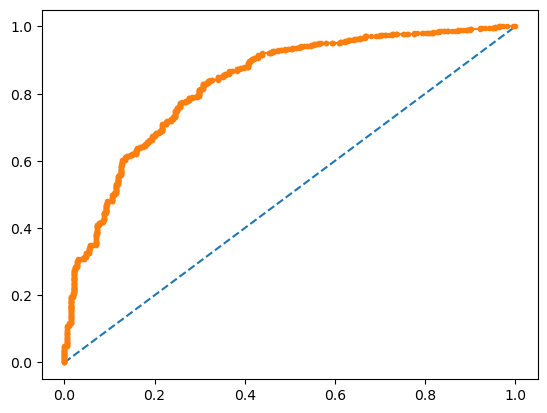

In [228]:
plt.plot([0,1], [0,1], linestyle='--')
#plot the roc curve for the model
plt.plot(fpr, tpr, marker='.')
plt.show()

In [229]:
probs_lr_test = log_model.predict_proba(X_test_scaled)[:, 1]

In [230]:
auc_lr_test = roc_auc_score(test_labels, probs_lr_test)

In [231]:
auc_lr_test

0.8257304193647856

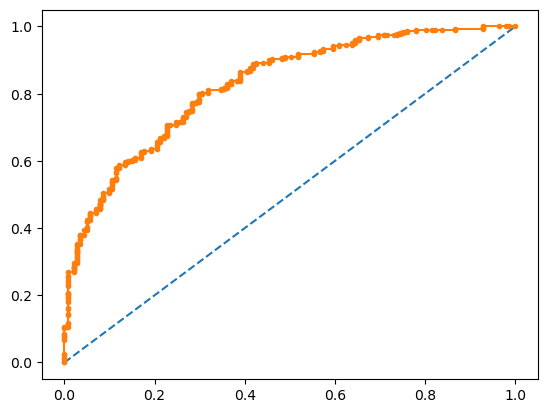

In [232]:
fpr, tpr, thresholds = roc_curve(test_labels, probs_lr_test, pos_label='Win')
plt.plot([0,1], [0,1], linestyle='--')
plt.plot(fpr, tpr, marker='.')
plt.show()

### Decision Tree

In [233]:
dt_model = DecisionTreeClassifier(criterion = 'gini', class_weight = 'balanced', random_state=1)
dt_model.fit(X_model_train, train_labels)
ytrain_pred_dt = dt_model.predict(X_model_train)
ytest_pred_dt = dt_model.predict(X_model_test)

In [234]:
print("Train Accuracy:", dt_model.score(X_model_train, train_labels))
print("Test Accuracy:", dt_model.score(X_model_test, test_labels))
print(confusion_matrix(test_labels, ytest_pred_dt))
print(classification_report(test_labels, ytest_pred_dt))

Train Accuracy: 1.0
Test Accuracy: 0.9304446978335233
[[111  30]
 [ 31 705]]
              precision    recall  f1-score   support

        Loss       0.78      0.79      0.78       141
         Win       0.96      0.96      0.96       736

    accuracy                           0.93       877
   macro avg       0.87      0.87      0.87       877
weighted avg       0.93      0.93      0.93       877



In [235]:
train_char_label = ['No', 'Yes']

In [236]:
Cricket_Tree_File = open('d:\cricket_tree.dot','w')

In [237]:
dot_data = tree.export_graphviz(dt_model, 
                                out_file= Cricket_Tree_File, 
                                feature_names=list(X_model_train), 
                                class_names=train_char_label)

In [238]:
Cricket_Tree_File.close()

In [239]:
clf_dt_model = DecisionTreeClassifier(criterion = 'gini', 
                                      class_weight = 'balanced', 
                                      random_state=1, 
                                      max_depth = 16, 
                                      min_samples_leaf=1, 
                                      min_samples_split=3)

In [240]:
clf_dt_model.fit(X_model_train, train_labels)

DecisionTreeClassifier(class_weight='balanced', max_depth=16,
                       min_samples_split=3, random_state=1)

In [241]:
cricket_tree_regularized = open('d:\cricket_tree_regularized.dot', 'w')
dot_data = tree.export_graphviz(clf_dt_model,
                                out_file = cricket_tree_regularized, 
                                feature_names=list(X_model_train), 
                                class_names=train_char_label)
cricket_tree_regularized.close()

In [242]:
clf_dt_model.feature_importances_

array([0.02711119, 0.04088076, 0.05120679, 0.07639368, 0.03414692,
       0.08053147, 0.01909618, 0.03584549, 0.04285613, 0.05653488,
       0.14215668, 0.04355188, 0.07735863, 0.03562034, 0.00945857,
       0.0032497 , 0.00984484, 0.00371556, 0.00500239, 0.        ,
       0.01852585, 0.00549292, 0.03972907, 0.        , 0.0050303 ,
       0.00703633, 0.0432624 , 0.01413516, 0.0722259 ])

In [243]:
feature_imp = pd.DataFrame(dt_model.feature_importances_, columns = ["imp"], index = X_model_train.columns)
feature_imp.sort_values(by = 'imp', ascending = False)
feature_imp[feature_imp['imp']>0.02]

,imp
Avg_team_Age,0.026072
Bowlers_in_team,0.036262
All_rounder_in_team,0.052923
Max_run_scored_1over,0.071628
Max_wicket_taken_1over,0.034973
Extra_bowls_bowled,0.077874
Min_run_scored_1over,0.032689
Max_run_given_1over,0.049884
extra_bowls_opponent,0.051857
player_highest_run,0.154736


In [244]:
ytrain_pred_pruned = clf_dt_model.predict(X_model_train)
ytest_pred_pruned = clf_dt_model.predict(X_model_test)

In [245]:
print(confusion_matrix(test_labels, ytest_pred_pruned))
print(classification_report(test_labels, ytest_pred_pruned))
print("Train Accuracy:",clf_dt_model.score(X_model_train, train_labels))
print("Test Accuracy:",clf_dt_model.score(X_model_test, test_labels))

[[111  30]
 [ 35 701]]
              precision    recall  f1-score   support

        Loss       0.76      0.79      0.77       141
         Win       0.96      0.95      0.96       736

    accuracy                           0.93       877
   macro avg       0.86      0.87      0.86       877
weighted avg       0.93      0.93      0.93       877

Train Accuracy: 0.9975562072336266
Test Accuracy: 0.9258836944127709


In [246]:
ytrain_pred_pruned_prob = clf_dt_model.predict_proba(X_model_train)
ytest_pred_pruned_prob = clf_dt_model.predict_proba(X_model_test)

In [247]:
ytrain_pred_pruned_prob

array([[0., 1.],
       [0., 1.],
       [0., 1.],
       ...,
       [1., 0.],
       [0., 1.],
       [0., 1.]])

In [248]:
probs = clf_dt_model.predict_proba(X_model_train)

In [249]:
probs = probs[:,1]

In [250]:
auc_train = roc_auc_score(train_labels, probs)

In [251]:
auc_train

0.9999734462986797

In [252]:
fpr, tpr, thresholds = roc_curve(train_labels, probs, pos_label='Win')

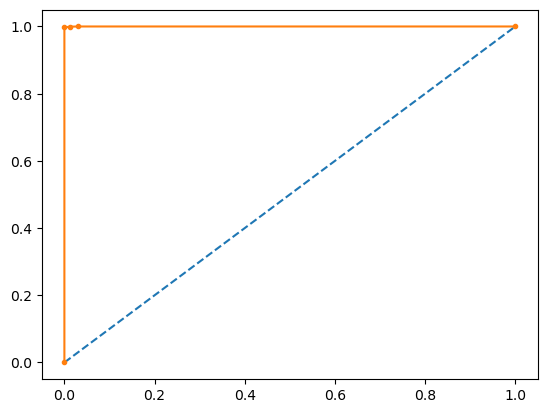

In [253]:
plt.plot([0,1], [0,1], linestyle='--')
#plot the roc curve for the model
plt.plot(fpr, tpr, marker='.')
plt.show()

In [254]:
probs = clf_dt_model.predict_proba(X_model_test)

In [255]:
probs = probs[:, 1]

In [256]:
auc_test = roc_auc_score(test_labels, probs)

In [257]:
auc_test

0.8714731729879741

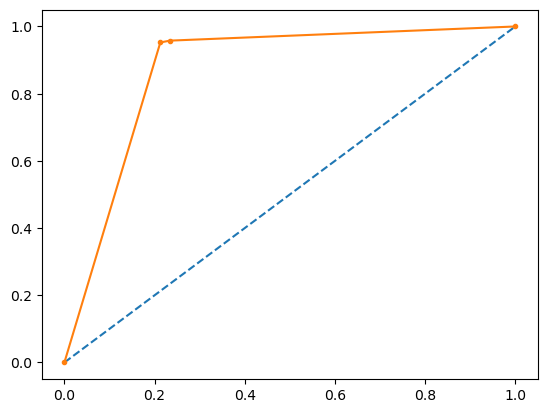

In [258]:
fpr, tpr, thresholds = roc_curve(test_labels, probs, pos_label='Win')
plt.plot([0,1], [0,1], linestyle='--')
plt.plot(fpr, tpr, marker='.')
plt.show()

### Random Forest

In [259]:
X_model.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2923 entries, 1 to 2929
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Avg_team_Age                    2923 non-null   float64
 1   Bowlers_in_team                 2923 non-null   Int64  
 2   All_rounder_in_team             2923 non-null   Int64  
 3   Max_run_scored_1over            2923 non-null   Int64  
 4   Max_wicket_taken_1over          2923 non-null   Int64  
 5   Extra_bowls_bowled              2923 non-null   Int64  
 6   Min_run_given_1over             2923 non-null   Int64  
 7   Min_run_scored_1over            2923 non-null   Int64  
 8   Max_run_given_1over             2923 non-null   Int64  
 9   extra_bowls_opponent            2923 non-null   Int64  
 10  player_highest_run              2923 non-null   Int64  
 11  Players_scored_zero             2923 non-null   Int64  
 12  player_highest_wicket           29

In [260]:
rf_model = RandomForestClassifier(n_estimators = 200, class_weight = 'balanced', random_state = 1, oob_score=True)

In [261]:
rf_model = rf_model.fit(X_model_train, train_labels)

In [262]:
rf_model.oob_score_

0.9467253176930597

In [263]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15],
    'max_features': [4, 5, 6],
    'min_samples_leaf': [5, 10, 15],
    'min_samples_split': [10, 20, 30],
    'class_weight': ['balanced']
    
}

In [264]:
rfcl = RandomForestClassifier()

In [265]:
grid_search = GridSearchCV(estimator = rfcl, param_grid = param_grid, cv = 3)

In [266]:
grid_search.fit(X_model_train, train_labels)

GridSearchCV(cv=3, estimator=RandomForestClassifier(),
             param_grid={'class_weight': ['balanced'], 'max_depth': [5, 10, 15],
                         'max_features': [4, 5, 6],
                         'min_samples_leaf': [5, 10, 15],
                         'min_samples_split': [10, 20, 30],
                         'n_estimators': [100, 200, 300]})

In [267]:
grid_search.best_params_

{'class_weight': 'balanced',
 'max_depth': 15,
 'max_features': 6,
 'min_samples_leaf': 5,
 'min_samples_split': 10,
 'n_estimators': 300}

In [268]:
grid_search.best_score_

0.8895405669599218

In [269]:
grid_search.best_estimator_

RandomForestClassifier(class_weight='balanced', max_depth=15, max_features=6,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=300)

In [270]:
best_grid = grid_search.best_estimator_

In [271]:
ytrain_predict_rf = best_grid.predict(X_model_train)
ytest_predict_rf = best_grid.predict(X_model_test)

In [272]:
print(confusion_matrix(test_labels, ytest_predict_rf))
print(classification_report(test_labels, ytest_predict_rf))
print("Train Accuracy:",best_grid.score(X_model_train, train_labels))
print("Test Accuracy:",best_grid.score(X_model_test, test_labels))

[[100  41]
 [ 36 700]]
              precision    recall  f1-score   support

        Loss       0.74      0.71      0.72       141
         Win       0.94      0.95      0.95       736

    accuracy                           0.91       877
   macro avg       0.84      0.83      0.83       877
weighted avg       0.91      0.91      0.91       877

Train Accuracy: 0.969208211143695
Test Accuracy: 0.9122006841505131


In [273]:
ytrain_predict_prob_rf = best_grid.predict_proba(X_model_train)
ytest_predict_prob_rf = best_grid.predict_proba(X_model_test)

In [274]:
ytrain_predict_prob_rf

array([[0.12250949, 0.87749051],
       [0.07621606, 0.92378394],
       [0.08829247, 0.91170753],
       ...,
       [0.59006098, 0.40993902],
       [0.10646403, 0.89353597],
       [0.03952533, 0.96047467]])

In [275]:
probs_rf = best_grid.predict_proba(X_model_train)

In [276]:
probs_rf = probs_rf [:,1]

In [277]:
auc_rf_train = roc_auc_score(train_labels, probs_rf)

In [278]:
auc_rf_train

0.995505343489829

In [279]:
fpr, tpr, thresholds = roc_curve(train_labels, probs_rf, pos_label='Win')

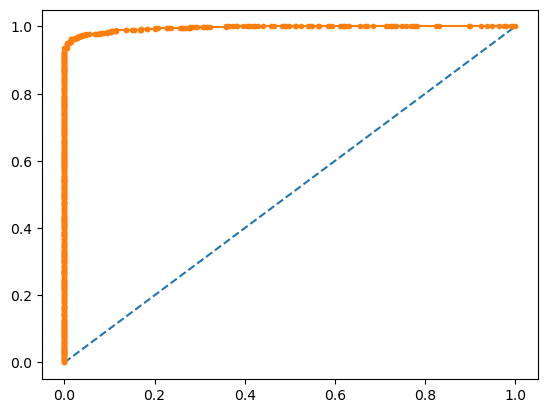

In [280]:
plt.plot([0,1], [0,1], linestyle='--')
#plot the roc curve for the model
plt.plot(fpr, tpr, marker='.')
plt.show()

In [281]:
probs_rf = best_grid.predict_proba(X_model_test)

In [282]:
probs_rf = probs_rf[:,1]

In [283]:
auc_rf_test = roc_auc_score(test_labels, probs_rf)

In [284]:
auc_rf_test

0.9314870490286772

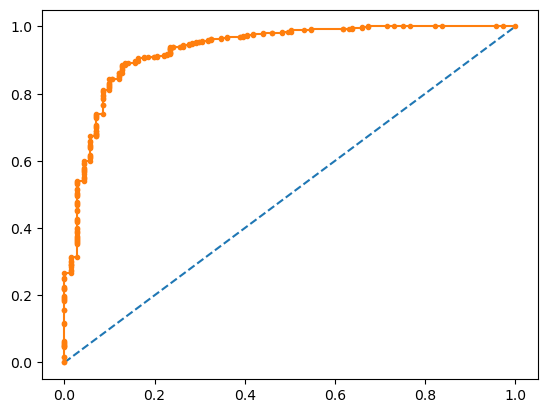

In [285]:
fpr, tpr, thresholds = roc_curve(test_labels, probs_rf, pos_label='Win')
plt.plot([0,1], [0,1], linestyle='--')
plt.plot(fpr, tpr, marker='.')
plt.show()

### Gradient Boosting

In [286]:
gb_model = GradientBoostingClassifier(random_state=1)
gb_model.fit(X_model_train, train_labels)

GradientBoostingClassifier(random_state=1)

In [287]:
ytrain_predict_gb = gb_model.predict(X_model_train)
ytest_predict_gb = gb_model.predict(X_model_test)

In [288]:
ytrain_predict_gb

array(['Win', 'Win', 'Win', ..., 'Win', 'Win', 'Win'], dtype=object)

In [289]:
print(confusion_matrix(test_labels, ytest_predict_gb))
print(classification_report(test_labels, ytest_predict_gb))
print("Train Accuracy:",gb_model.score(X_model_train, train_labels))
print("Test Accuracy:",gb_model.score(X_model_test, test_labels))

[[ 55  86]
 [ 11 725]]
              precision    recall  f1-score   support

        Loss       0.83      0.39      0.53       141
         Win       0.89      0.99      0.94       736

    accuracy                           0.89       877
   macro avg       0.86      0.69      0.73       877
weighted avg       0.88      0.89      0.87       877

Train Accuracy: 0.9227761485826002
Test Accuracy: 0.8893956670467503


In [290]:
param_grid_gb = {
    'learning_rate': [0.05, 0.1,0.2],
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15],
    'max_features': [4, 5, 6],
    'min_samples_leaf': [5, 10, 15],
    'min_samples_split': [10, 20, 30]
    
}

In [291]:
gbcl = GradientBoostingClassifier()

In [292]:
grid_search_gb = GridSearchCV(estimator = gbcl, param_grid = param_grid_gb, cv = 3)

In [293]:
grid_search_gb.fit(X_model_train, train_labels)

GridSearchCV(cv=3, estimator=GradientBoostingClassifier(),
             param_grid={'learning_rate': [0.05, 0.1, 0.2],
                         'max_depth': [5, 10, 15], 'max_features': [4, 5, 6],
                         'min_samples_leaf': [5, 10, 15],
                         'min_samples_split': [10, 20, 30],
                         'n_estimators': [100, 200, 300]})

In [294]:
grid_search_gb.best_params_

{'learning_rate': 0.05,
 'max_depth': 15,
 'max_features': 4,
 'min_samples_leaf': 10,
 'min_samples_split': 30,
 'n_estimators': 300}

In [295]:
grid_search_gb.best_score_

0.9252199413489736

In [296]:
grid_search_gb.best_estimator_

GradientBoostingClassifier(learning_rate=0.05, max_depth=15, max_features=4,
                           min_samples_leaf=10, min_samples_split=30,
                           n_estimators=300)

In [297]:
best_grid_gb = grid_search_gb.best_estimator_

In [298]:
ytrain_predict_gb1 = best_grid_gb.predict(X_model_train)
ytest_predict_gb1 = best_grid_gb.predict(X_model_test)

In [299]:
print(confusion_matrix(test_labels, ytest_predict_gb1))
print(classification_report(test_labels, ytest_predict_gb1))
print("Train Accuracy:",best_grid_gb.score(X_model_train, train_labels))
print("Test Accuracy:",best_grid_gb.score(X_model_test, test_labels))

[[110  31]
 [  6 730]]
              precision    recall  f1-score   support

        Loss       0.95      0.78      0.86       141
         Win       0.96      0.99      0.98       736

    accuracy                           0.96       877
   macro avg       0.95      0.89      0.92       877
weighted avg       0.96      0.96      0.96       877

Train Accuracy: 1.0
Test Accuracy: 0.9578107183580388


In [300]:
ytrain_predict_gb2 = best_grid_gb.predict_proba(X_model_train)
ytest_predict_gb2 = best_grid_gb.predict_proba(X_model_test)

In [301]:
ytrain_predict_gb2

array([[3.86719512e-04, 9.99613280e-01],
       [8.14105981e-05, 9.99918589e-01],
       [1.53915300e-04, 9.99846085e-01],
       ...,
       [9.68202312e-01, 3.17976875e-02],
       [2.93956310e-04, 9.99706044e-01],
       [3.83084696e-05, 9.99961692e-01]])

In [302]:
probs_gb = best_grid_gb.predict_proba(X_model_train)

In [303]:
probs_gb = probs_gb[:,1]

In [304]:
auc_train_gb = roc_auc_score(train_labels, probs_gb)

In [305]:
auc_train_gb

1.0

In [306]:
fpr, tpr, thresholds = roc_curve(train_labels, probs_gb, pos_label='Win')

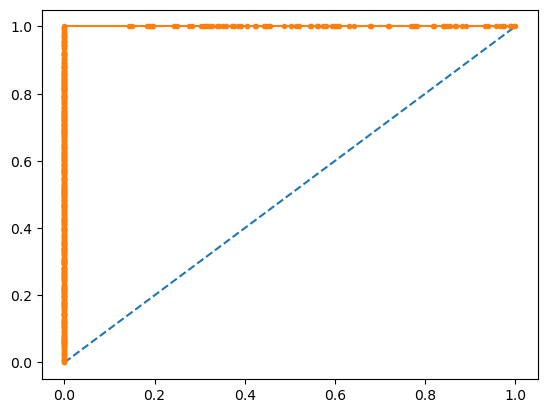

In [307]:
plt.plot([0,1], [0,1], linestyle='--')
#plot the roc curve for the model
plt.plot(fpr, tpr, marker='.')
plt.show()

In [308]:
probs_gb = best_grid_gb.predict_proba(X_model_test)

In [309]:
probs_gb = probs_gb[:,1]

In [310]:
auc_gb_test = roc_auc_score(test_labels, probs_gb)

In [311]:
auc_gb_test

0.9499113475177305

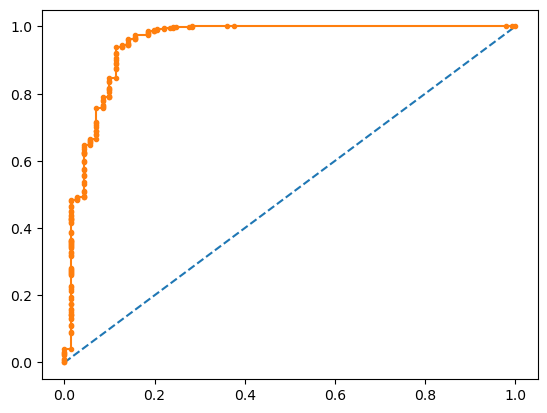

In [312]:
fpr, tpr, thresholds = roc_curve(test_labels, probs_gb, pos_label='Win')
plt.plot([0,1], [0,1], linestyle='--')
plt.plot(fpr, tpr, marker='.')
plt.show()